# Linear regression

## Univariate linear regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 0. Environment setup / 环境与路径配置

This block fixes three reproducibility problems of the original notebook:

1. **No working-directory dependence** — every path is resolved from the project root
   (the folder that contains `data/`), so the notebook runs identically whether Jupyter
   is started from the project root or from `notebooks/`.
2. **Reproducibility** — one global `RANDOM_STATE` is declared here and reused by every
   later random split.
3. **Chinese font fallback** — `SimHei` is requested first, but the code degrades to
   another installed CJK font (or DejaVu Sans) instead of crashing. If no CJK font
   exists the Chinese labels render as boxes, so every label also carries an English
   gloss.

In [2]:
# ---------- 1. project root ----------
def find_project_root(start=None):
    """Return the folder that contains data/, searching upward from `start`."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Project root not found: no 'data' folder at or above {start}. "
        "Run the notebook from inside the project directory."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULT_DIR = PROJECT_ROOT / "outputs" / "results"

for directory in (FIG_DIR, RESULT_DIR):
    directory.mkdir(parents=True, exist_ok=True)  # created by code, not by hand

RANDOM_STATE = 42

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR    :", DATA_DIR)
print("FIG_DIR     :", FIG_DIR)
print("RESULT_DIR  :", RESULT_DIR)
print("RANDOM_STATE:", RANDOM_STATE)

PROJECT_ROOT: D:\WIT\6th semester\AI\Linear regression
DATA_DIR    : D:\WIT\6th semester\AI\Linear regression\data
FIG_DIR     : D:\WIT\6th semester\AI\Linear regression\outputs\figures
RESULT_DIR  : D:\WIT\6th semester\AI\Linear regression\outputs\results
RANDOM_STATE: 42


In [3]:
# ---------- 2. matplotlib font handling (Chinese labels) ----------
from matplotlib import font_manager

CJK_FONT_CANDIDATES = ["SimHei", "Microsoft YaHei", "Noto Sans CJK SC", "Arial Unicode MS"]
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
selected_fonts = [name for name in CJK_FONT_CANDIDATES if name in available_fonts]

plt.rcParams["font.sans-serif"] = selected_fonts + ["DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False  # keep the normal minus sign

if selected_fonts:
    print("CJK font in use:", selected_fonts[0])
else:
    print("No CJK font found -> Chinese labels fall back to DejaVu Sans (boxes). "
          "Install SimHei/Microsoft YaHei, or read the English gloss in each label.")

CJK font in use: Microsoft YaHei


### Reusable CSV loader

`load_csv` reads from `DATA_DIR` and validates the required Chinese columns, so a wrong
path or a renamed header fails immediately with a message naming the missing item
instead of producing a confusing error deep inside a model cell.

In [4]:
def load_csv(filename, required_columns=None):
    """Load a CSV from DATA_DIR and check that its required columns exist.

    Raises FileNotFoundError naming the missing file, or ValueError naming the
    missing column(s).
    """
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Data file not found: {path}. "
            f"Expected the working copy inside {DATA_DIR}."
        )

    df = pd.read_csv(path)

    missing = [column for column in (required_columns or []) if column not in df.columns]
    if missing:
        raise ValueError(
            f"{filename} is missing required column(s): {missing}. "
            f"Columns found: {list(df.columns)}"
        )

    print(f"Loaded {filename}: shape={df.shape}, columns={list(df.columns)}")
    return df

In [5]:
data = load_csv("regress_data1.csv", ["人口", "收益"])
data1 = data.copy()  # raw snapshot: no model code may mutate the inspected data
data.head()

Loaded regress_data1.csv: shape=(97, 2), columns=['人口', '收益']


,人口,收益
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


## 1. Dataset inspection and validation / 数据检查与校验

Before any model is fitted, every dataset is inspected once: shape, columns, `head()`,
`describe()`, missing values, dtypes, and the Pearson correlation between each feature and
the target. One reusable helper serves both datasets, and it **fails loudly** with a
`ValueError` naming the offending column — a broken CSV can never silently reach a model
cell. Nothing is modelled or plotted in this block.

In [6]:
def summarize_dataset(df, name, features, target):
    """Inspect `df` for a regression task; raise ValueError when the data is unusable.

    Prints shape / columns / head / describe / missing values / dtypes, and returns a
    summary table (one row per modelled column) with the correlation to the target.
    """
    columns = list(features) + [target]

    print(f"===== {name} =====")
    print(f"rows x columns : {df.shape[0]} x {df.shape[1]}")
    print(f"columns        : {list(df.columns)}")
    print(f"features       : {features}")
    print(f"target         : {target}")

    # --- guard 1: empty dataset ---
    if df.shape[0] == 0:
        raise ValueError(f"{name}: dataset has 0 rows - nothing to train on.")

    # --- guard 2: required columns present ---
    missing = [column for column in columns if column not in df.columns]
    if missing:
        raise ValueError(
            f"{name}: missing required column(s) {missing}. "
            f"Columns found: {list(df.columns)}"
        )

    selected = df[columns]

    # --- guard 3: numeric columns ---
    non_numeric = [c for c in columns if not pd.api.types.is_numeric_dtype(selected[c])]
    if non_numeric:
        raise ValueError(
            f"{name}: non-numeric column(s) {non_numeric} "
            f"(dtypes: {[str(selected[c].dtype) for c in non_numeric]})."
        )

    # --- guard 4: missing values ---
    missing_counts = {c: int(selected[c].isna().sum()) for c in columns}
    if any(missing_counts.values()):
        offenders = {c: n for c, n in missing_counts.items() if n > 0}
        raise ValueError(f"{name}: missing values detected {offenders}.")

    # --- guard 5: infinite values ---
    non_finite_counts = {c: int(np.sum(~np.isfinite(selected[c]))) for c in columns}
    if any(non_finite_counts.values()):
        offenders = {c: n for c, n in non_finite_counts.items() if n > 0}
        raise ValueError(f"{name}: non-finite (inf/-inf) values detected {offenders}.")

    display(selected.head())
    display(selected.describe())
    print("missing values per modelled column:", missing_counts)
    print("dtypes:", {c: str(selected[c].dtype) for c in columns})

    rows = []
    for column in columns:
        series = selected[column]
        is_target = column == target
        rows.append({
            "column": column,
            "role": "target" if is_target else "feature",
            "count": int(series.count()),
            "mean": float(series.mean()),
            "std": float(series.std()),
            "min": float(series.min()),
            "max": float(series.max()),
            "corr_with_target": np.nan if is_target else float(series.corr(selected[target])),
        })
    summary = pd.DataFrame(rows).set_index("column")
    print("summary:")
    print(summary.to_string())
    return summary


FEATURES_1, TARGET_1 = ["人口"], "收益"      # 人口 population -> 收益 profit
summary_1 = summarize_dataset(data1, "data1 (regress_data1.csv)", FEATURES_1, TARGET_1)
summary_1

===== data1 (regress_data1.csv) =====
rows x columns : 97 x 2
columns        : ['人口', '收益']
features       : ['人口']
target         : 收益


,人口,收益
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


,人口,收益
count,97.000000,97.000000
mean,8.159800,5.839135
std,3.869884,5.510262
min,5.026900,-2.680700
25%,5.707700,1.986900
50%,6.589400,4.562300
75%,8.578100,7.046700
max,22.203000,24.147000


missing values per modelled column: {'人口': 0, '收益': 0}
dtypes: {'人口': 'float64', '收益': 'float64'}
summary:
           role  count      mean       std     min     max  corr_with_target
column                                                                      
人口      feature     97  8.159800  3.869884  5.0269  22.203          0.837873
收益       target     97  5.839135  5.510262 -2.6807  24.147               NaN


,role,count,mean,std,min,max,corr_with_target
column,,,,,,,
人口,feature,97,8.159800,3.869884,5.0269,22.203,0.837873
收益,target,97,5.839135,5.510262,-2.6807,24.147,NaN


In [7]:
data.describe()

,人口,收益
count,97.000000,97.000000
mean,8.159800,5.839135
std,3.869884,5.510262
min,5.026900,-2.680700
25%,5.707700,1.986900
50%,6.589400,4.562300
75%,8.578100,7.046700
max,22.203000,24.147000


What does the data look like

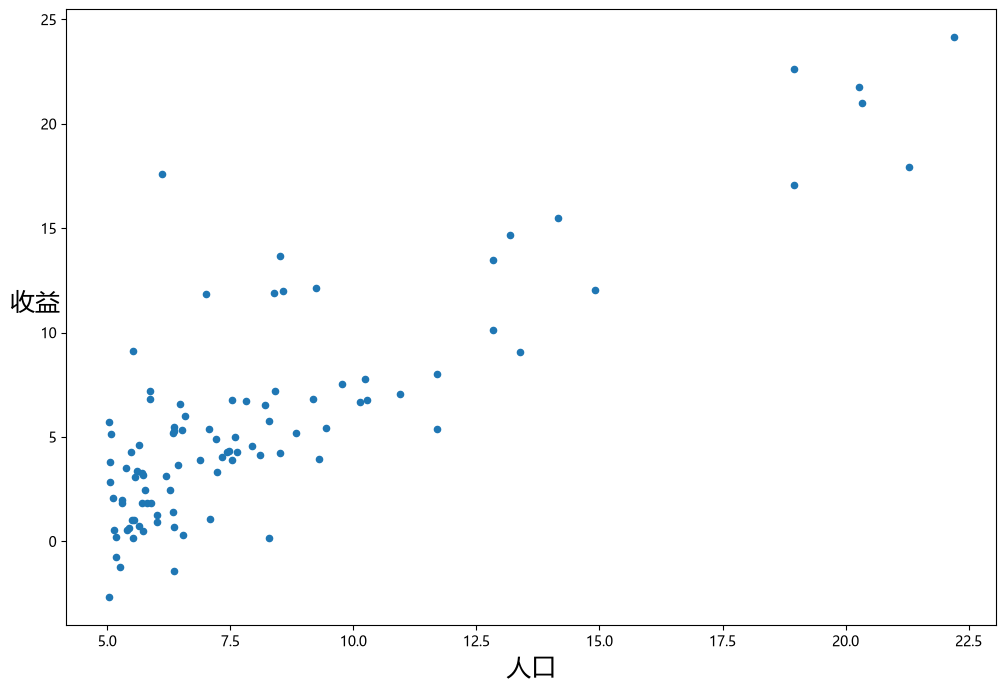

In [8]:
data.plot(kind='scatter', x='人口', y='收益', figsize=(12,8))
plt.xlabel('人口', fontsize=18)
plt.ylabel('收益', rotation=0, fontsize=18)
plt.show()

## 2. Univariate linear regression with batch gradient descent / 单变量线性回归（批量梯度下降）

**Data:** `data1` = `regress_data1.csv`，97 rows，feature 人口 / Population (10,000s) → target 收益 / Profit ($10,000s)。
**Implementation:** NumPy only —— 本节的拟合路径不使用 scikit-learn。

### 假设函数 / Hypothesis

$$h_w(x) = w_0 + w_1 x$$

把截距写进矩阵里，就可以对 $w_0$ 和 $w_1$ 用同一条公式：

$$h_w(X) = Xw,\quad
X = \begin{bmatrix} 1 & x^{(1)} \\ \vdots & \vdots \\ 1 & x^{(m)} \end{bmatrix},\quad
w = \begin{bmatrix} w_0 \\ w_1 \end{bmatrix}$$

第一列全为 1，专门用来承载截距 $w_0$。

### 代价函数 / Cost（half mean-squared error）

$$J(w) = \frac{1}{2m}\sum_{i=1}^{m}\bigl(h_w(x^{(i)}) - y^{(i)}\bigr)^2
       = \frac{1}{2m}\,(Xw - y)^\top (Xw - y)$$

前面的 $\tfrac12$ 只是为了让求导后的系数更简洁，它不改变最小值的位置。
**这是训练代价（training cost），不是测试指标**，不能拿来当泛化性能报告。

### 更新规则 / Update rule（批量梯度下降）

$$w := w - \alpha\,\frac{1}{m}\,X^\top (Xw - y)
\qquad\Longleftrightarrow\qquad
w_j := w_j - \alpha\,\frac{1}{m}\sum_{i=1}^{m}\bigl(h_w(x^{(i)}) - y^{(i)}\bigr)\,x_j^{(i)}
\;\;\text{对所有 } j \text{ 同时执行}$$

**为什么必须"同时更新"：** $\frac{1}{m}X^\top(Xw-y)$ 是**同一个** $w$ 处的梯度向量。
如果先更新 $w_0$、再用更新后的 $w_0$ 去算 $w_1$ 的梯度，得到的既不是旧点的梯度也不是新点的梯度，
算法就变成顺序/坐标式更新，而不再是真正的批量梯度下降。实现上很简单：
先用**一个不变的** $w$ 算出完整梯度向量，再整块减去 $\alpha\cdot$梯度。

**为什么还要关心特征尺度：** 梯度 $\frac{1}{m}X^\top(Xw-y)$ 与特征列的量级成正比。
当特征量级相差很大时（见第 3 节 `data2`：面积 852–4478 对 房间数 1–5），
同一个学习率 $\alpha$ 对大尺度特征可能已经震荡发散，对小尺度特征却几乎不动，
代价曲面被拉成狭长的"峡谷"，收敛极慢。所以多变量部分要先做标准化；
单变量这里只有一个特征、量级温和（人口 5.03–22.20），可以直接用原始值训练。


### 代价函数实现 / Cost function

`computeCost` 是一个**纯函数**：只返回一个 Python float，不打印、不画图、不修改入参，
因此它可以安全地在训练循环里被反复调用（每轮记录一次代价）。


In [9]:
def computeCost(X, y, w):
    """Half mean-squared error  J(w) = 1/(2m) * sum((X @ w - y)^2).

    Pure function: returns a Python float, prints nothing, plots nothing and
    does not modify its arguments.

    Shapes: X (m, n), y (m, 1) or (m,), w (n, 1) or (n,).
    ndarray and np.matrix inputs are both accepted (the multivariable cell in
    Part 3 still builds np.matrix objects).
    """
    X = np.asarray(X, dtype=float)                  # (m, n)
    y = np.asarray(y, dtype=float).reshape(-1, 1)   # (m, 1)
    w = np.asarray(w, dtype=float).reshape(-1, 1)   # (n, 1)

    errors = X @ w - y                              # (m, 1)
    return float(np.sum(errors ** 2) / (2.0 * X.shape[0]))


### 设计矩阵 / Design matrix

`X1 = [1, 人口]`，`y1 = 收益`，统一用 `np.asarray(..., dtype=float)` 构造并显式整形，
避免后面出现 `np.matrix` 与 ndarray 混算的问题。原始 DataFrame `data1` 不会被修改。
初始权重取 $w = [0, 0]$，与原始实验保持一致。


In [10]:
# ---------- design matrix for data1 / data1 的设计矩阵 ----------
m1 = data1.shape[0]

X1 = np.column_stack([
    np.ones(m1, dtype=float),                # 截距列 / intercept column
    np.asarray(data1["人口"], dtype=float),  # 特征 / feature  人口
]).astype(float)                             # -> (m, 2)

y1 = np.asarray(data1["收益"], dtype=float).reshape(-1, 1)   # 目标 / target  收益 -> (m, 1)
w1_initial = np.zeros((X1.shape[1], 1), dtype=float)         # w = [w0, w1] = [0, 0] -> (2, 1)

print("X1 shape:", X1.shape, "| y1 shape:", y1.shape, "| w1_initial shape:", w1_initial.shape)
print("first 5 rows of X1:\n", X1[:5])
print("first 5 values of y1:", y1[:5].ravel())


X1 shape: (97, 2) | y1 shape: (97, 1) | w1_initial shape: (2, 1)
first 5 rows of X1:
 [[1.     6.1101]
 [1.     5.5277]
 [1.     8.5186]
 [1.     7.0032]
 [1.     5.8598]]
first 5 values of y1: [17.592   9.1302 13.662  11.854   6.8233]


### 超参数 / Hyperparameters

| 变量 | 值 | 控制什么 |
| --- | --- | --- |
| `ALPHA_GD`（学习率 $\alpha$） | 0.01 | 每一步沿负梯度方向走多远。太大 → 代价震荡甚至发散；太小 → 收敛很慢。 |
| `ITERS_GD`（迭代次数） | 1500 | 权重更新执行多少轮。这里固定 1500 轮（未使用早停），便于与原始实验的输出对照。 |

这两个量都是**训练过程的设置**，既不是模型参数，也不是评价指标。
原名 `alpha` / `iters` 改为大写，是为了和后面 Ridge 正则化里的 `alpha` 区分开。


In [11]:
ALPHA_GD = 0.01     # 学习率 / learning rate
ITERS_GD = 1500     # 迭代次数 / number of batch gradient descent iterations

print(f"ALPHA_GD = {ALPHA_GD}   ITERS_GD = {ITERS_GD}")


ALPHA_GD = 0.01   ITERS_GD = 1500


In [12]:
# 训练前的代价 / cost before training (w = [0, 0])
initial_cost = computeCost(X1, y1, w1_initial)
print(f"data1 · TRAINING cost · before training: J([0, 0]) = {initial_cost:.4f}")


data1 · TRAINING cost · before training: J([0, 0]) = 32.0727


### 批量梯度下降 / Batch gradient descent

$$w := w - \alpha\,\frac{1}{m}\,X^\top (Xw - y)$$

实现要点：**一次迭代只算一个梯度**（来自当前这一份完整的 $w$），然后整块更新所有 $w_j$；
全程向量化，不对训练样本做 Python 循环；每轮结束记录一次代价；入参 `w` 会被复制，
调用方的 `w` 不会被意外改写。


In [13]:
def batch_gradientDescent(X, y, w, alpha, iters):
    """Batch gradient descent for linear regression.

    Returns
    -------
    w_final      : (n, 1) ndarray — fitted weights
    cost_history : (iters,) ndarray — J(w) recorded after every iteration

    Notes
    -----
    * TRUE batch update: each iteration computes one gradient from a single,
      consistent weight vector and subtracts it in one step, so every w_j is
      updated simultaneously (no sequential / in-place coordinate updates).
    * Fully vectorised: no Python loop over training examples.
    * The caller's `w` is never mutated (defensive copy on entry).
    """
    X = np.asarray(X, dtype=float)                        # (m, n)
    y = np.asarray(y, dtype=float).reshape(-1, 1)         # (m, 1)
    w = np.asarray(w, dtype=float).reshape(-1, 1).copy()  # (n, 1) — defensive copy

    m = X.shape[0]
    cost_history = np.zeros(int(iters), dtype=float)

    for i in range(int(iters)):
        gradient = (X.T @ (X @ w - y)) / m   # (n, 1) — one gradient, from current w only
        w = w - alpha * gradient             # simultaneous update of every w_j
        cost_history[i] = computeCost(X, y, w)

    return w, cost_history


In [14]:
g1, cost_history1 = batch_gradientDescent(X1, y1, w1_initial, ALPHA_GD, ITERS_GD)

intercept_gd = float(g1[0, 0])   # w0
slope_gd = float(g1[1, 0])       # w1
final_cost = computeCost(X1, y1, g1)

print("data1 (regress_data1.csv) · batch gradient descent · TRAINING cost")
print(f"  hyperparameters      : alpha = {ALPHA_GD}, iters = {ITERS_GD}")
print(f"  w0 (intercept)       = {intercept_gd:.4f}")
print(f"  w1 (slope)           = {slope_gd:.4f}")
print(f"  J(w) before training = {initial_cost:.4f}")
print(f"  J(w) after  training = {final_cost:.4f}")
print(f"  fitted model         : 收益 = {intercept_gd:.4f} + {slope_gd:.4f} * 人口")


data1 (regress_data1.csv) · batch gradient descent · TRAINING cost


  hyperparameters      : alpha = 0.01, iters = 1500
  w0 (intercept)       = -3.6303
  w1 (slope)           = 1.1664
  J(w) before training = 32.0727
  J(w) after  training = 4.4834
  fitted model         : 收益 = -3.6303 + 1.1664 * 人口


**与原始笔记本保存的输出对照：** 参考值为 $w_0 \approx -3.6303$、$w_1 \approx 1.1664$、
$J \approx 4.4834$。上面重新执行得到的数字应落在这组值附近；若只在小数点后 3–4 位有差异，
那是浮点运算顺序/类型的正常差异，不影响结论；若偏差较大，则必须回头检查设计矩阵、
代价定义或更新规则。


### 收敛性检查 / Convergence check

$J(w)$ 是凸的二次函数，只要 $\alpha$ 不过大，代价就应**单调下降**并逐渐变平。
下面的单元格直接对 `cost_history1` 做差分：若出现上升（超出容差）或 NaN/inf，就说明发散，
需要调小 `ALPHA_GD` 重跑。


In [15]:
diffs = np.diff(cost_history1)
max_increase = float(diffs.max()) if diffs.size else 0.0
is_finite = bool(np.isfinite(cost_history1).all())
is_monotone = is_finite and (max_increase <= 1e-12)

print(f"iterations recorded        : {cost_history1.size}")
print(f"first -> last cost         : {cost_history1[0]:.4f} -> {cost_history1[-1]:.4f}")
print(f"largest step-to-step change: {diffs.min():.3e} (min) / {max_increase:.3e} (max)")
print(f"all costs finite           : {is_finite}")
print(f"monotonically decreasing   : {is_monotone}")
print(f"total reduction            : {cost_history1[0] - cost_history1[-1]:.4f} "
      f"({100 * (1 - cost_history1[-1] / cost_history1[0]):.1f} %)")

if not is_finite:
    print("DIVERGED: cost contains NaN/inf -> reduce ALPHA_GD and re-run.")
else:
    assert is_monotone, (
        f"cost increased by up to {max_increase:.3e} in one iteration "
        f"-> ALPHA_GD={ALPHA_GD} is too large; lower it and re-run."
    )
    print("OK: cost never increased -> batch gradient descent converged monotonically.")


iterations recorded        : 1500
first -> last cost         : 6.7372 -> 4.4834
largest step-to-step change: -8.056e-01 (min) / -2.320e-05 (max)
all costs finite           : True
monotonically decreasing   : True
total reduction            : 2.2538 (33.5 %)
OK: cost never increased -> batch gradient descent converged monotonically.


### 图 1 · 拟合直线 / Fitted line

散点是 `data1` 的原始观测（人口 vs 收益），红线是批量梯度下降得到的 $h_w(x)=w_0+w_1x$。
斜率 $w_1>0$，说明人口规模越大、收益越高，与相关系数约 0.838 的观察一致。


saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\gd_data1_fitted_line.png


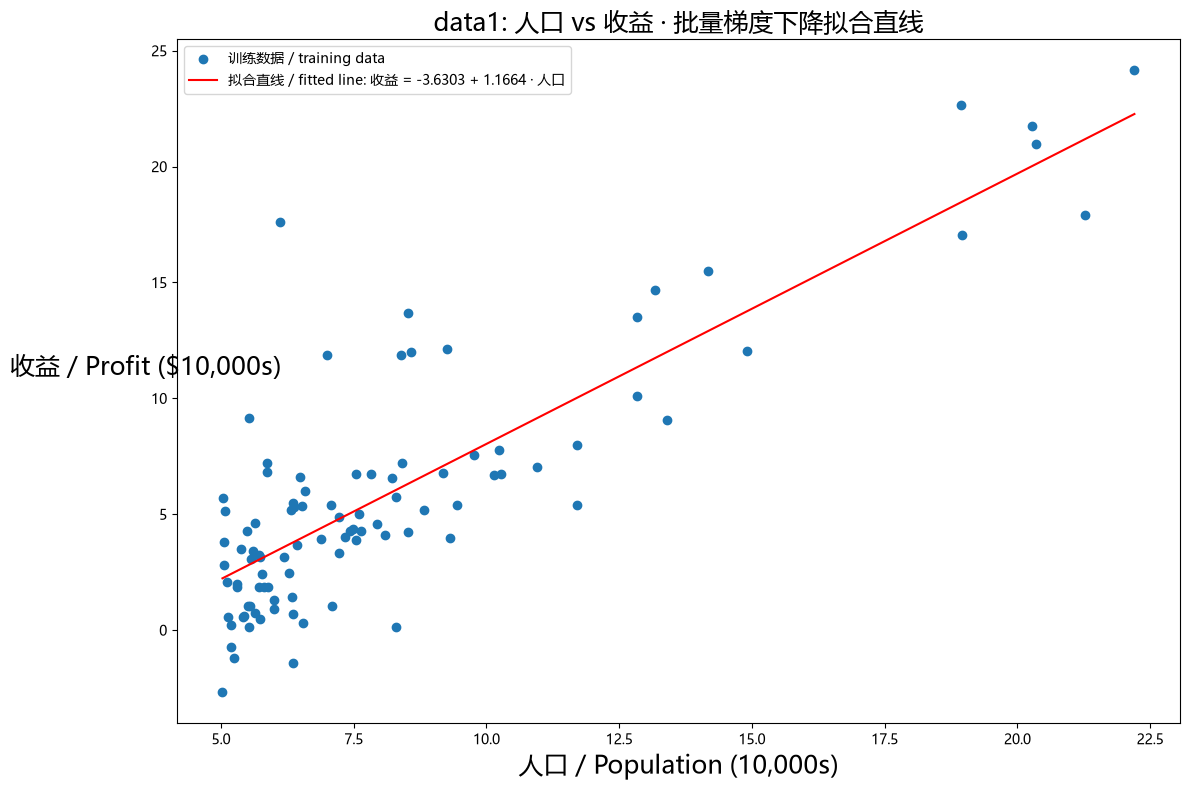

In [16]:
x_line = np.linspace(data1["人口"].min(), data1["人口"].max(), 100)
y_line = intercept_gd + slope_gd * x_line

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(data1["人口"], data1["收益"], label="训练数据 / training data")
ax.plot(x_line, y_line, "r",
        label=f"拟合直线 / fitted line: 收益 = {intercept_gd:.4f} + {slope_gd:.4f} · 人口")
ax.set_xlabel("人口 / Population (10,000s)", fontsize=18)
ax.set_ylabel("收益 / Profit ($10,000s)", rotation=0, fontsize=18)
ax.set_title("data1: 人口 vs 收益 · 批量梯度下降拟合直线", fontsize=18)
ax.legend(loc=2)
fig.tight_layout()

fig_path = FIG_DIR / "gd_data1_fitted_line.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print("saved:", fig_path)
plt.show()


### 图 2 · 训练代价曲线 / Training cost history

纵轴是**训练代价** $J(w)$（不是测试误差）。曲线应当先快速下降、后逐渐变平：
前几百轮下降最快，之后逼近最小二乘解，说明学习率 0.01 对这组数据是合适的。


saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\gd_data1_cost_history.png


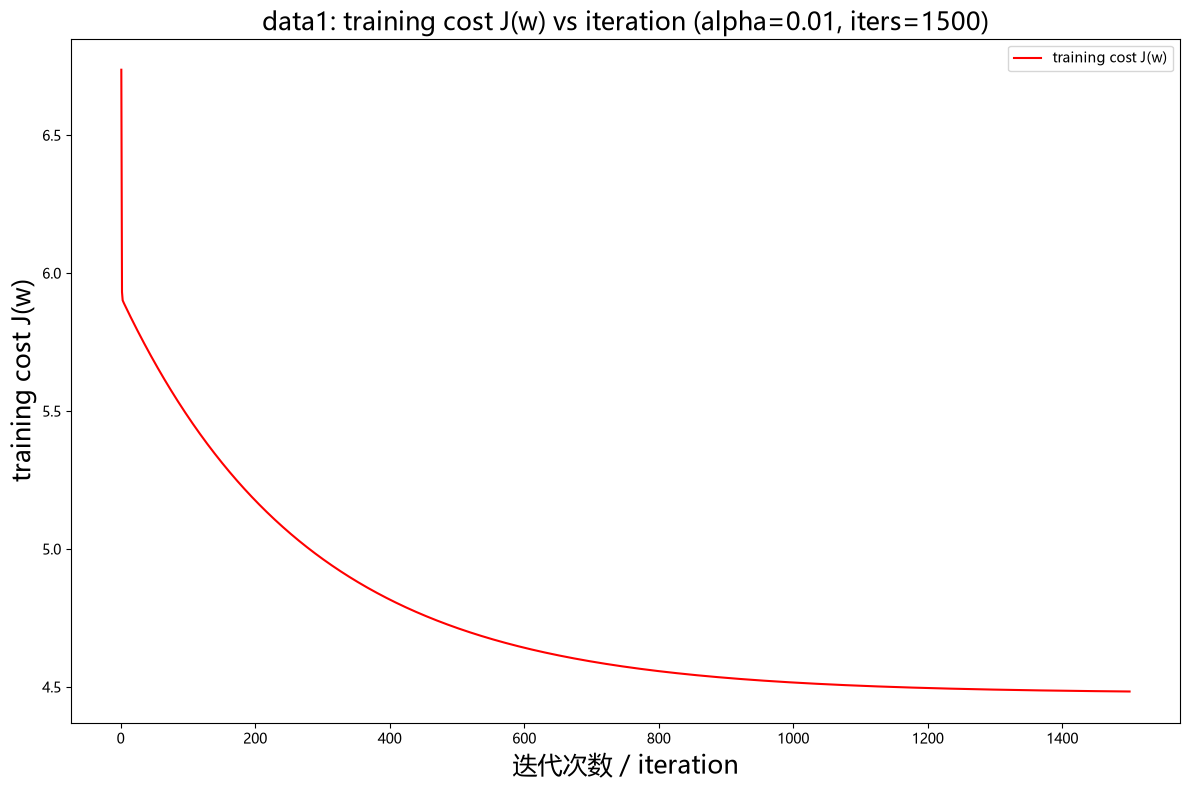

In [17]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(np.arange(1, cost_history1.size + 1), cost_history1, "r", label="training cost J(w)")
ax.set_xlabel("迭代次数 / iteration", fontsize=18)
ax.set_ylabel("training cost J(w)", fontsize=18)
ax.set_title(f"data1: training cost J(w) vs iteration (alpha={ALPHA_GD}, iters={ITERS_GD})",
             fontsize=18)
ax.legend(loc=1)
fig.tight_layout()

fig_path = FIG_DIR / "gd_data1_cost_history.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print("saved:", fig_path)
plt.show()


In [18]:
## multiple linear regression

The exercise also includes a house price dataset with 2 variables (the size of the house, the number of bedrooms) and a goal (the price of the house). We analyze the data set using techniques we've already applied.

In [19]:
data2 = load_csv("regress_data2.csv", ["面积", "房间数", "价格"])
data2.head()

Loaded regress_data2.csv: shape=(47, 3), columns=['面积', '房间数', '价格']


,面积,房间数,价格
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


## 2. Second dataset: housing prices / 房价数据集

`regress_data2.csv` is the multivariable dataset: `面积` (living area, 852-4478 ft²) and
`房间数` (number of rooms, 1-5) predict `价格` (price, 169900-699900). Note the very
different scales — a price is ~10⁵ while a room count is ~10⁰ — which is exactly why
feature standardization is needed later (Step 07 keeps it leakage-safe inside a Pipeline).
Area correlates with price far more strongly than room count does.

In [20]:
FEATURES_2, TARGET_2 = ["面积", "房间数"], "价格"   # 面积 area, 房间数 rooms -> 价格 price
summary_2 = summarize_dataset(data2, "data2 (regress_data2.csv)", FEATURES_2, TARGET_2)
summary_2

===== data2 (regress_data2.csv) =====
rows x columns : 47 x 3
columns        : ['面积', '房间数', '价格']
features       : ['面积', '房间数']
target         : 价格


,面积,房间数,价格
0,2104,3,399900
1,1600,3,329900
2,2400,3,369000
3,1416,2,232000
4,3000,4,539900


,面积,房间数,价格
count,47.000000,47.000000,47.000000
mean,2000.680851,3.170213,340412.659574
std,794.702354,0.760982,125039.899586
min,852.000000,1.000000,169900.000000
25%,1432.000000,3.000000,249900.000000
50%,1888.000000,3.000000,299900.000000
75%,2269.000000,4.000000,384450.000000
max,4478.000000,5.000000,699900.000000


missing values per modelled column: {'面积': 0, '房间数': 0, '价格': 0}
dtypes: {'面积': 'int64', '房间数': 'int64', '价格': 'int64'}
summary:
           role  count           mean            std       min       max  corr_with_target
column                                                                                    
面积      feature     47    2000.680851     794.702354     852.0    4478.0          0.854988
房间数     feature     47       3.170213       0.760982       1.0       5.0          0.442261
价格       target     47  340412.659574  125039.899586  169900.0  699900.0               NaN


,role,count,mean,std,min,max,corr_with_target
column,,,,,,,
面积,feature,47,2000.680851,794.702354,852.0,4478.0,0.854988
房间数,feature,47,3.170213,0.760982,1.0,5.0,0.442261
价格,target,47,340412.659574,125039.899586,169900.0,699900.0,NaN


For this task, we add another preprocessing step - feature normalization. This is easy for pandas

### Guard self-test / 校验自测

The guards above are executed once on purpose-broken copies of `data2` to show that a
corrupted CSV stops the workflow with a named error instead of producing a silent result.
None of these frames is used for modelling.

In [21]:
def expect_error(label, df, features, target):
    try:
        summarize_dataset(df, label, features, target)
    except ValueError as error:
        print(f"[{label}] ValueError -> {error}")
    else:
        print(f"[{label}] NO ERROR RAISED (guard failed!)")


# a) a missing value in 价格
broken = data2.copy()
broken.loc[0, "价格"] = np.nan
expect_error("guard: NaN value", broken, FEATURES_2, TARGET_2)

# b) a non-numeric feature column
broken = data2.copy()
broken["面积"] = broken["面积"].astype(str)
expect_error("guard: non-numeric column", broken, FEATURES_2, TARGET_2)

# c) an empty dataset
expect_error("guard: empty dataset", data2.iloc[0:0], FEATURES_2, TARGET_2)

# d) a renamed (missing) target column
broken = data2.rename(columns={"价格": "售价"})
expect_error("guard: missing target column", broken, FEATURES_2, TARGET_2)

===== guard: NaN value =====
rows x columns : 47 x 3
columns        : ['面积', '房间数', '价格']
features       : ['面积', '房间数']
target         : 价格
[guard: NaN value] ValueError -> guard: NaN value: missing values detected {'价格': 1}.
===== guard: non-numeric column =====
rows x columns : 47 x 3
columns        : ['面积', '房间数', '价格']
features       : ['面积', '房间数']
target         : 价格
[guard: non-numeric column] ValueError -> guard: non-numeric column: non-numeric column(s) ['面积'] (dtypes: ['str']).
===== guard: empty dataset =====
rows x columns : 0 x 3
columns        : ['面积', '房间数', '价格']
features       : ['面积', '房间数']
target         : 价格
[guard: empty dataset] ValueError -> guard: empty dataset: dataset has 0 rows - nothing to train on.
===== guard: missing target column =====
rows x columns : 47 x 3
columns        : ['面积', '房间数', '售价']
features       : ['面积', '房间数']
target         : 价格
[guard: missing target column] ValueError -> guard: missing target column: missing required column(s) ['价格']

In [22]:
data2 = (data2 - data2.mean()) / data2.std()
data2.head()

,面积,房间数,价格
0,0.130010,-0.223675,0.475747
1,-0.504190,-0.223675,-0.084074
2,0.502476,-0.223675,0.228626
3,-0.735723,-1.537767,-0.867025
4,1.257476,1.090417,1.595389


Now we repeat the preprocessing steps from Part 1 and run the linear regression program on the new data set.

In [23]:
# add ones column
data2.insert(0, 'Ones', 1)

# set X (training data) and y (target variable)
cols = data2.shape[1]
X2 = data2.iloc[:,0:cols-1]
y2 = data2.iloc[:,cols-1:cols]

# convert to matrices and initialize theta
X2 = np.matrix(X2.values)
y2 = np.matrix(y2.values)
w2 = np.matrix(np.array([0,0,0]))

# perform linear regression on the data set
g2, cost2 = batch_gradientDescent(X2, y2, w2, ALPHA_GD, ITERS_GD)

# get the cost (error) of the model
computeCost(X2, y2, g2)

0.130686706060959

We can also quickly view the training progress of this one.

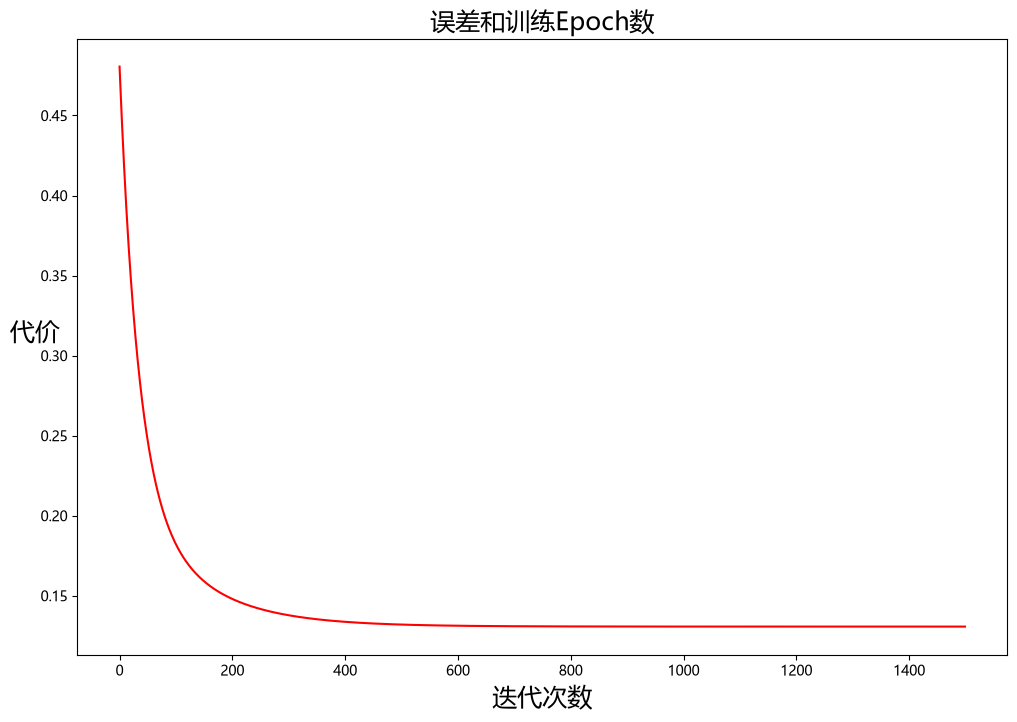

In [24]:
fig, ax = plt.subplots(figsize=(12,8))
ax.plot(np.arange(ITERS_GD), cost2, 'r')
ax.set_xlabel('迭代次数', fontsize=18)
ax.set_ylabel('代价', rotation=0, fontsize=18)
ax.set_title('误差和训练Epoch数', fontsize=18)
plt.show()

## 3. scikit-learn 线性回归 / scikit-learn LinearRegression

前几节是手写实现：自己拼设计矩阵、自己写梯度、自己解方程。这一节改用 scikit-learn 的
`LinearRegression`，在**同一份数据**上再做一次，并补上实验要求里缺失的**多变量**模型
（`面积 + 房间数 → 价格`）。

### 输入约定：raw frames（不含常数列）/ Raw input convention

| 变量 | 内容 | 形状 |
| --- | --- | --- |
| `X1_raw` | `data1[["人口"]]` | (97, 1) |
| `y1_raw` | `data1["收益"]` | (97,) |
| `X2_raw` | `data2_raw[["面积", "房间数"]]` | (47, 2) |
| `y2_raw` | `data2_raw["价格"]` | (47,) |

统一用 pandas DataFrame / Series 传入，这样 `model.coef_` 可以直接按列名读出，
打印与报告里都能带上特征名，不必人工记"第 0 列是谁"。

### 截距约定 / Intercept convention（本项目规则）

| 实现 | 截距怎么来 |
| --- | --- |
| 手写 NumPy（第 2、3、5 节） | 设计矩阵里**显式放一列 1**，权重 `w[0]` 即截距 |
| scikit-learn 估计器 | **不**给常数列，交给 `fit_intercept=True`（默认），截距在 `model.intercept_` |

两者都只有**一个**截距，只是摆放位置不同。本 notebook 后面的
*sklearn ↔ NumPy LSM 一致性校验* 会用数字证明它们解出的是同一组参数。

### 重复截距会发生什么 / Duplicate intercept

如果既手动加一列 1、又让 `fit_intercept=True` 自己拟合截距，模型里就同时存在两个常数项
（`c_manual · 1 + ... + c_estimator`），而且**只有其中一个受约束**：

- **`LinearRegression`**：预测值不变（两个常数项可以互相抵消），但解不再唯一——
  手动常数列与估计器的截距列完全共线，$X^\top X$ 奇异，`coef_[0]` 失去了"截距"的含义，
  手写实现与 sklearn 的参数再也没法逐项对照。
- **`Ridge`**：更严重。估计器**不会**惩罚自己的 `intercept_`，却**会**惩罚手动加的那列常数；
  于是同一个截距被两套规则对待，`alpha` 越大，这个多余的常数被拉向 0 的力越强，
  截距的数值取决于一个本该与截距无关的 `alpha`。

**规则：scikit-learn 估计器只用自带的 `fit_intercept`，绝不额外传入手动常数列。**
本节把所有 sklearn 调用点统一改成 raw frames（包括下面第 4 节的 `Ridge`）。

In [25]:
# ---------- raw feature / target frames: 不含任何手动常数列 ----------
# 注意：上面的 data2 已被就地标准化并插入了 'Ones' 列，这里重新读一份未处理的原始副本。
data2_raw = load_csv("regress_data2.csv", FEATURES_2 + [TARGET_2])

X1_raw = data1[FEATURES_1]      # DataFrame -> 列名可以直接配到 model.coef_
y1_raw = data1[TARGET_1]        # Series
X2_raw = data2_raw[FEATURES_2]
y2_raw = data2_raw[TARGET_2]

for name, frame in [("X1_raw", X1_raw), ("X2_raw", X2_raw)]:
    constant_columns = [column for column in frame.columns if frame[column].nunique() == 1]
    assert not constant_columns, f"{name} still contains a constant column: {constant_columns}"
    print(f"{name}: shape={frame.shape}, columns={list(frame.columns)} -> 无常数列 / no constant column")

print(f"y1_raw: {y1_raw.name} {y1_raw.shape} | y2_raw: {y2_raw.name} {y2_raw.shape}")

Loaded regress_data2.csv: shape=(47, 3), columns=['面积', '房间数', '价格']


X1_raw: shape=(97, 1), columns=['人口'] -> 无常数列 / no constant column
X2_raw: shape=(47, 2), columns=['面积', '房间数'] -> 无常数列 / no constant column
y1_raw: 收益 (97,) | y2_raw: 价格 (47,)


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


def report_sklearn(model, X, y, dataset, target_name):
    """Print intercept + named coefficients and TRAINING metrics for a fitted sklearn model.

    `X` must be the RAW feature frame (no manually added constant column), so the
    estimator's own intercept is the only intercept and every coef_ maps to one feature.
    """
    assert X.shape[1] == model.coef_.size, "expected exactly one coefficient per raw feature"
    predictions = model.predict(X)
    intercept = float(model.intercept_)

    print(f"{dataset} · {type(model).__name__} · TRAINING metrics")
    print(f"  fit_intercept = {model.fit_intercept} | n_features_in_ = {model.n_features_in_} "
          "(raw features only, no manually added ones column)")
    print(f"  intercept w0  = {intercept:,.4f}")
    for name, coefficient in zip(X.columns, model.coef_):
        print(f"  {name:<14} = {coefficient:>14,.4f}")
    print(f"  TRAINING MSE  = {mean_squared_error(y, predictions):,.4f}")
    print(f"  TRAINING R^2  = {r2_score(y, predictions):.4f}")
    print("  fitted model  : " + f"{target_name} = {intercept:,.4f}" + "".join(
        f" + {coefficient:,.4f} * {name}" for name, coefficient in zip(X.columns, model.coef_)))
    return predictions


# ---------- 3.1 单变量 / univariate: 人口 -> 收益 ----------
sk_model_1 = LinearRegression()   # fit_intercept=True (default): sklearn owns the only intercept
sk_model_1.fit(X1_raw, y1_raw)

pred1_sklearn = report_sklearn(sk_model_1, X1_raw, y1_raw, "data1 (regress_data1.csv)", TARGET_1)

data1 (regress_data1.csv) · LinearRegression · TRAINING metrics
  fit_intercept = True | n_features_in_ = 1 (raw features only, no manually added ones column)
  intercept w0  = -3.8958
  人口             =         1.1930
  TRAINING MSE  = 8.9539
  TRAINING R^2  = 0.7020
  fitted model  : 收益 = -3.8958 + 1.1930 * 人口


### 3.1 单变量：拟合直线 / Fitted line (sklearn)

红线是 sklearn `LinearRegression` 在**训练集**上的预测值，散点是 `data1` 的原始观测。
因为是单特征，预测值按 `人口` 升序连线；这只是训练拟合的可视化，**不代表测试集表现**。

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\sklearn_data1_fitted_line.png


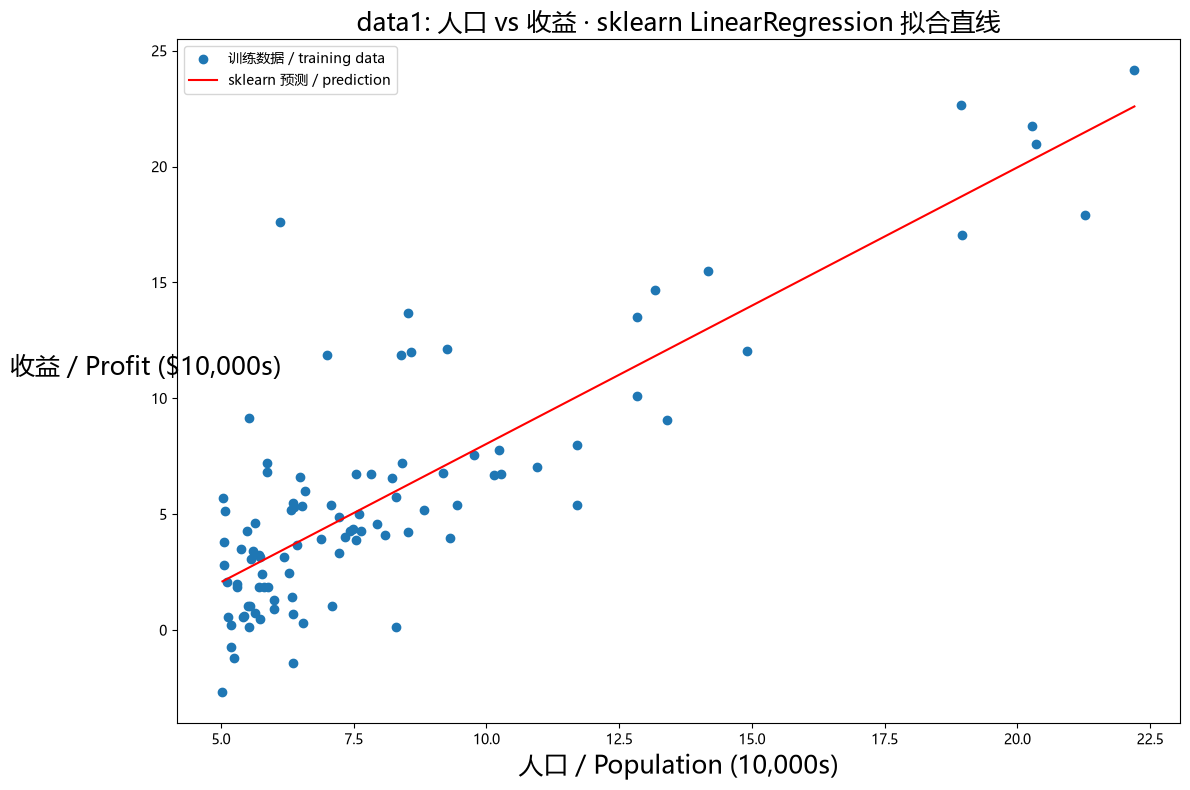

In [27]:
order_sklearn = np.argsort(X1_raw["人口"].to_numpy())     # 按 x 升序连线，避免锯齿
x_sorted = X1_raw["人口"].to_numpy()[order_sklearn]
f_sklearn = pred1_sklearn[order_sklearn]

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(data1["人口"], data1["收益"], label="训练数据 / training data")
ax.plot(x_sorted, f_sklearn, "r", label="sklearn 预测 / prediction")
ax.set_xlabel("人口 / Population (10,000s)", fontsize=18)
ax.set_ylabel("收益 / Profit ($10,000s)", rotation=0, fontsize=18)
ax.set_title("data1: 人口 vs 收益 · sklearn LinearRegression 拟合直线", fontsize=18)
ax.legend(loc=2)
fig.tight_layout()

fig_path = FIG_DIR / "sklearn_data1_fitted_line.png"
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
print("saved:", fig_path)
plt.show()

### 3.2 多变量：面积 + 房间数 → 价格 / Multivariable fit

这一步正是原来 notebook 缺失的部分：之前的 sklearn 段落只用了单变量 `X, y`。
这里用**未标准化**的原始值拟合（同样是 raw frame，无常数列），
所以 `coef_` 可以直接读成"每多 1 平方英尺 / 每多 1 间房，价格平均变化多少美元"。

In [28]:
# ---------- 3.2 多变量 / multivariable: 面积 + 房间数 -> 价格 ----------
sk_model_2 = LinearRegression()   # 同一个约定：截距交给 fit_intercept，不传常数列
sk_model_2.fit(X2_raw, y2_raw)

pred2_sklearn = report_sklearn(sk_model_2, X2_raw, y2_raw, "data2 (regress_data2.csv)", TARGET_2)

data2 (regress_data2.csv) · LinearRegression · TRAINING metrics
  fit_intercept = True | n_features_in_ = 2 (raw features only, no manually added ones column)
  intercept w0  = 89,597.9095
  面积             =       139.2107
  房间数            =    -8,738.0191
  TRAINING MSE  = 4,086,560,101.2057
  TRAINING R^2  = 0.7329
  fitted model  : 价格 = 89,597.9095 + 139.2107 * 面积 + -8,738.0191 * 房间数


### 3.3 原始单位 vs 标准化单位的系数 / Raw vs standardized coefficients

**原始单位（3.2 的结果）** 系数读作：

- `面积`：**美元 / 平方英尺** —— 面积每增加 1 ft²，价格平均变动这么多美元；
- `房间数`：**美元 / 间** —— 在面积不变的前提下，每多 1 间房，价格平均变动这么多美元。

两个系数量纲不同，**大小不能直接比较，更不是"特征重要性"**。`房间数` 的系数绝对值小（本例中为负），
只说明在**已经控制面积之后**，房间数带来的**增量**信息有限——这与第 2 节的相关性一致
（面积 ~0.855 ≫ 房间数 ~0.442，而两者本身正相关），并不等于"房间数不影响价格"。

**标准化单位**：把每个特征换成"标准差"单位后再拟合，系数就变成
"该特征变化 1 个标准差时，价格变化多少美元"，量纲统一后才**大致**可以比较影响大小。
线性模型对特征做仿射变换不改变拟合优度，因此标准化前后 $R^2$ 完全相同——
这说明标准化改变的是**解释方式**，不是模型能力。

> ⚠️ 下面的标准化**只用于解释系数**，不参与任何评估：`StandardScaler` 在这里看到了全部 47 条样本，
> 属于数据泄漏。第 7 节会把它放进 `Pipeline`，只在每个训练折内部 fit。

In [29]:
# ---------- 3.3 仅用于解释：换单位的系数 / interpretation only, NOT a validation result ----------
# 不用 StandardScaler：把 X 除以各列标准差（ddof=0，与 StandardScaler 一致）只是**换单位**，
# 有截距时不影响拟合值。这样本节不存在任何"在全量数据上 fit 过的预处理器"，
# 符合第 5 节的防泄漏约定（凡是学到的预处理只能出现在 Pipeline 里）。
X2_sd = X2_raw.std(ddof=0)
X2_per_sd = X2_raw / X2_sd                                   # 1 unit = 1 SD
sk_model_2_std = LinearRegression().fit(X2_per_sd, y2_raw)   # y stays in dollars

print("data2 · sklearn LinearRegression · X in SD units, y in dollars · TRAINING metrics")
print("  feature      1 SD of feature      $ / 1 SD       $ / raw unit")
for name, sd, coef_std, coef_raw in zip(FEATURES_2, X2_sd, sk_model_2_std.coef_, sk_model_2.coef_):
    print(f"  {name:<10}{sd:>14,.1f}{coef_std:>18,.1f}{coef_raw:>18,.4f}")

print(f"  TRAINING R^2 (X in SD units) = {sk_model_2_std.score(X2_per_sd, y2_raw):.4f}"
      f" | (raw X) = {sk_model_2.score(X2_raw, y2_raw):.4f}"
      "  -> identical: rescaling X changes the units, not the fit")
print("  NOTE: $/1 SD 只用于比较量纲不同的特征，仍然不是重要性排序；")
print("        这里没有 fit 任何预处理器，防泄漏的标准化（Pipeline）见第 5 节。")

data2 · sklearn LinearRegression · X in SD units, y in dollars · TRAINING metrics
  feature      1 SD of feature      $ / 1 SD       $ / raw unit
  面积                 786.2         109,447.8          139.2107
  房间数                  0.8          -6,578.4       -8,738.0191
  TRAINING R^2 (X in SD units) = 0.7329 | (raw X) = 0.7329  -> identical: rescaling X changes the units, not the fit
  NOTE: $/1 SD 只用于比较量纲不同的特征，仍然不是重要性排序；
        这里没有 fit 任何预处理器，防泄漏的标准化（Pipeline）见第 5 节。


## $L_2$regularization
$J (  { w } ) = \frac { 1 } { 2 } \sum _ { i = 1 } ^ { m } ( h _ { w} ( x ^ { ( i ) } ) - y ^ { ( i ) } ) ^ { 2 } + \lambda \sum _ { j = 1 } ^ { n } w_ { j } ^ { 2 }$，此时称作`Ridge Regression`：


本节沿用第 3 节的输入约定：`Ridge` 同样只接收原始特征，截距由 `fit_intercept` 自己拟合，
因此不会被 $\lambda$ 惩罚（这正是"不手动加常数列"对 Ridge 最关键的地方）。

In [30]:
from sklearn.linear_model import Ridge

# 同一个截距约定：只给原始特征，截距由估计器拟合，因此不会被 alpha 惩罚
ridge_model_1 = Ridge()
ridge_model_1.fit(X1_raw, y1_raw)

print(f"data1 (regress_data1.csv) · Ridge(alpha={ridge_model_1.alpha}) · TRAINING metrics")
print(f"  intercept  = {float(ridge_model_1.intercept_):.4f}   <- 不参与正则化 / not penalized")
print(f"  人口 (coef)= {float(ridge_model_1.coef_[0]):.4f}")

data1 (regress_data1.csv) · Ridge(alpha=1.0) · TRAINING metrics
  intercept  = -3.8890   <- 不参与正则化 / not penalized
  人口 (coef)= 1.1922


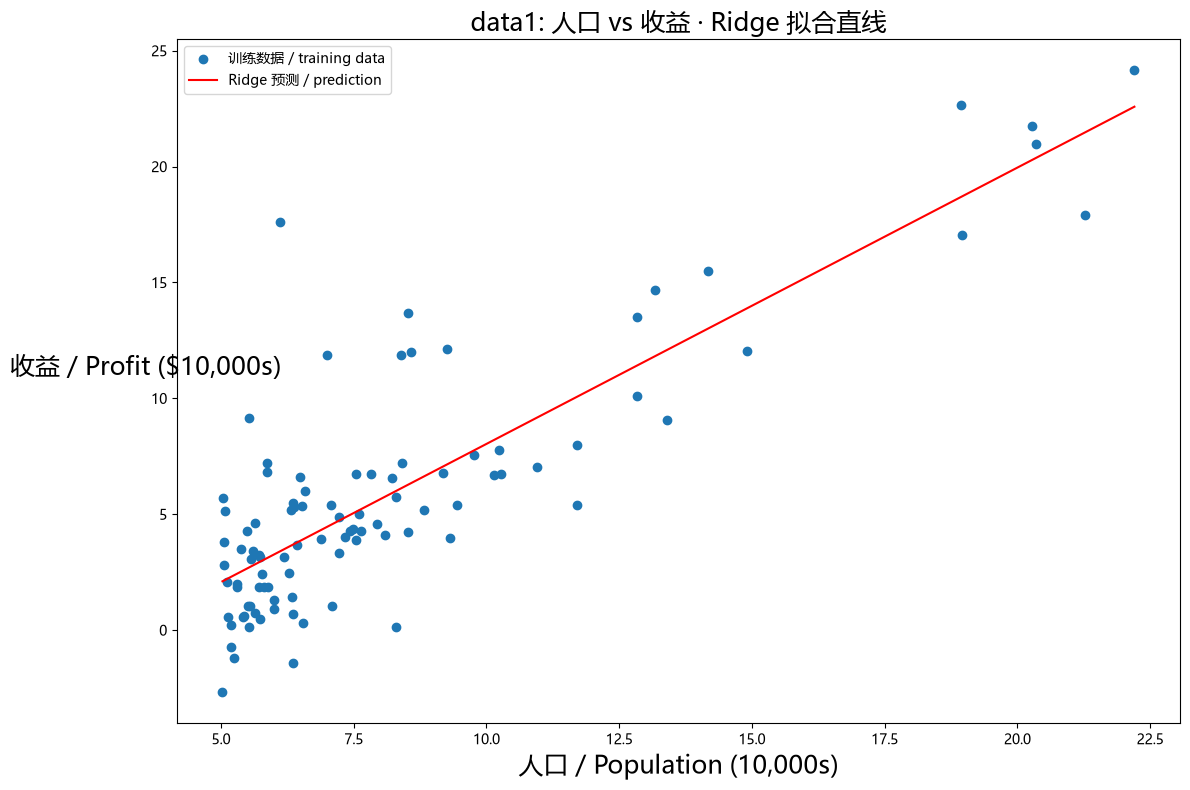

In [31]:
order_ridge = np.argsort(X1_raw["人口"].to_numpy())
x_ridge = X1_raw["人口"].to_numpy()[order_ridge]
f_ridge = ridge_model_1.predict(X1_raw)[order_ridge]

fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(data1["人口"], data1["收益"], label="训练数据 / training data")
ax.plot(x_ridge, f_ridge, "r", label="Ridge 预测 / prediction")
ax.set_xlabel("人口 / Population (10,000s)", fontsize=18)
ax.set_ylabel("收益 / Profit ($10,000s)", rotation=0, fontsize=18)
ax.set_title("data1: 人口 vs 收益 · Ridge 拟合直线", fontsize=18)
ax.legend(loc=2)
fig.tight_layout()
plt.show()

### α 扫描：简单回归 data1 / Ridge alpha sweep (VALIDATION metrics)

`Ridge` 的 `alpha` 是唯一的超参数。下面用**5 折交叉验证**扫描 50 个
`np.logspace(-3, 2, 50)` 的候选值，指标是 RMSE（由 `neg_mean_squared_error` 取负再开方）。

关键点：**`StandardScaler` 被放进 `Pipeline`**，所以每一折只在该折的训练部分上计算均值/标准差，
再用它去变换同一折的验证部分——预处理不会看到验证折，因此没有泄漏。
多变量版本与完整说明在第 5 节。

In [32]:
# ---------- data1 的 α 扫描：预处理放进 Pipeline，每折各自 fit ----------
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 同一个 KFold 对象：shuffle=True + 固定 seed -> 每次切分完全一致，候选之间可比
CV_FOLDS = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas = np.logspace(-3, 2, 50)


def ridge_pipeline(alpha):
    """Scaler + Ridge as ONE estimator: the scaler is fitted on each training fold only."""
    return Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=alpha))])


rmse_mean_1, rmse_std_1 = [], []
for alpha in alphas:
    fold_rmse = np.sqrt(-cross_val_score(ridge_pipeline(alpha), X1_raw, y1_raw, cv=CV_FOLDS,
                                         scoring="neg_mean_squared_error"))
    rmse_mean_1.append(fold_rmse.mean())
    rmse_std_1.append(fold_rmse.std())

rmse_mean_1, rmse_std_1 = np.array(rmse_mean_1), np.array(rmse_std_1)
best_idx_1 = int(np.argmin(rmse_mean_1))

print(f"data1 (regress_data1.csv) · Ridge α 扫描 · KFold(5, shuffle=True, random_state={RANDOM_STATE})")
print("  metric = VALIDATION RMSE (5-fold CV on all 97 rows) — 不是测试集分数")
print(f"  best alpha = {alphas[best_idx_1]:.4g} | CV RMSE = {rmse_mean_1[best_idx_1]:.4f}"
      f" ± {rmse_std_1[best_idx_1]:.4f} (SD across folds)")

data1 (regress_data1.csv) · Ridge α 扫描 · KFold(5, shuffle=True, random_state=42)
  metric = VALIDATION RMSE (5-fold CV on all 97 rows) — 不是测试集分数
  best alpha = 0.001 | CV RMSE = 3.0044 ± 0.5180 (SD across folds)


saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\ridge_alpha_sweep_data1.png


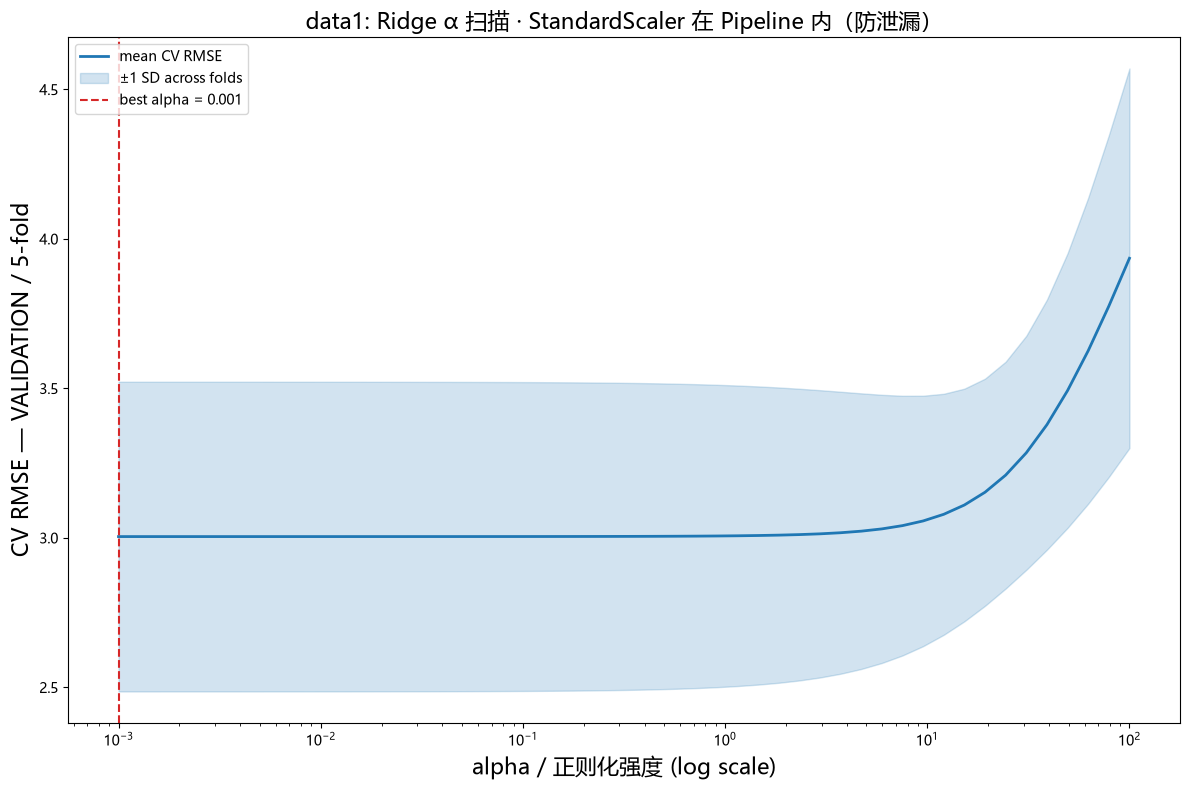

In [33]:
# ---------- α vs CV RMSE（对数横轴） ----------
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(alphas, rmse_mean_1, color="tab:blue", linewidth=2, label="mean CV RMSE")
ax.fill_between(alphas, rmse_mean_1 - rmse_std_1, rmse_mean_1 + rmse_std_1,
                color="tab:blue", alpha=0.2, label="±1 SD across folds")
ax.axvline(alphas[best_idx_1], color="tab:red", linestyle="--",
           label=f"best alpha = {alphas[best_idx_1]:.4g}")
ax.set_xscale("log")
ax.set_xlabel("alpha / 正则化强度 (log scale)", fontsize=16)
ax.set_ylabel("CV RMSE — VALIDATION / 5-fold", fontsize=16)
ax.set_title("data1: Ridge α 扫描 · StandardScaler 在 Pipeline 内（防泄漏）", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()

ridge_fig_1 = FIG_DIR / "ridge_alpha_sweep_data1.png"
fig.savefig(ridge_fig_1, dpi=150, bbox_inches="tight")
print("saved:", ridge_fig_1)
plt.show()

## Least squares / 最小二乘法（正规方程）

梯度下降是"一步步走到最低点"，最小二乘法则**一步解出**最低点。两者在本节用同一份数据、
同一个代价函数相减比较。

### 正规方程是怎么来的 / Derivation

训练代价（与第 2 节完全一致）：

$$J(w) = \frac{1}{2m}(Xw-y)^\top(Xw-y)$$

对 $w$ 求梯度（用到 $\nabla_w \tfrac12\|Xw-y\|^2 = X^\top(Xw-y)$）：

$$\nabla_w J(w) = \frac{1}{m}X^\top(Xw-y)$$

$J$ 是凸函数，最小值出现在梯度为 0 的地方，于是令上式为 0：

$$X^\top X\,w = X^\top y \qquad\Longrightarrow\qquad w^{*} = (X^\top X)^{-1}X^\top y \quad(\text{当 } X^\top X \text{ 可逆时，即 } X \text{ 列满秩})$$

这就是**正规方程（normal equation）**。注意第 2 节的梯度下降更新式里有完全相同的
$X^\top(Xw-y)$——二者优化的是同一个目标，只是一个迭代逼近、一个直接令其为 0。

### 为什么不写 inv(X.T @ X) / Why lstsq or pinv

1. **条件数被平方**：$\mathrm{cond}(X^\top X)=\mathrm{cond}(X)^2$。本来接近共线的列，
   平方之后可能直接淹没有效数字，得到的系数与真值相差很远，而程序不会报错。
2. **奇异矩阵会崩**：只要有一列是其它列的线性组合（重复特征、one-hot 陷阱、样本数少于特征数），
   $X^\top X$ 不可逆，`np.linalg.inv` 抛 `LinAlgError`；若只是"接近"奇异，则更糟——
   它会返回一个看似正常但数值错误的解。
3. **lstsq 用 SVD 求解**：`np.linalg.lstsq(X, y, rcond=None)` 即使在秩亏时也返回
   **最小范数解**（minimum-norm solution），并把有效秩 `rank` 报告出来——我们据此发出警告，
   而不是崩溃或悄悄给出错误的答案。`np.linalg.pinv(X)` 基于同一套 SVD，可以作为交叉校验。

### 什么时候用哪一个 / Closed form vs iterative

| | 梯度下降 GD | 正规方程 / lstsq |
| --- | --- | --- |
| 求解方式 | 迭代，需要 $\alpha$ 与迭代次数 | 一次求解，没有超参数 |
| 每步代价 | 每次迭代 $O(mn)$ | 一次 $O(mn^2+n^3)$ |
| 特征数 $n$ 很大（$\gtrsim 10^4$） | 仍然可行 | $n^3$ 迅速成为瓶颈 |
| 样本数 $m$ 极大 | mini-batch 可扩展 | 需要整份 $X$ 常驻内存 |
| 特征尺度 | 敏感，通常需要标准化 | 不敏感（但也建议标准化） |
| 数值行为 | 逐渐逼近，$\alpha$ 过大可能发散 | 满秩时精确到机器精度；秩亏时给最小范数解 |

本实验 $n$ 很小（1~2 个特征），因此两种方法都可以轻松求解，**正好用来互相对照**。


### 稳定的 LSM 实现 / Stable implementation

返回值与第 2 节的 `batch_gradientDescent` **保持同一约定**：形状为 `(n, 1)` 的列向量，
顺序 `[w0, w1, ...]`（截距在前），因此可以直接与梯度下降的结果相减。
诊断信息（秩、rank-deficiency 警告、pinv 交叉校验）以打印形式给出，不进入返回值。


In [34]:
def LSM(X, y):
    """Least-squares (normal-equation) solution using a numerically stable solver.

        w* = argmin_w ||X w - y||^2   <->   (X.T @ X) w = X.T @ y

    Solved with np.linalg.lstsq (SVD based) instead of the textbook
    inv(X.T @ X) @ X.T @ y, because forming X.T @ X squares the condition
    number and fails outright when the design matrix is singular.

    Returns a column vector of shape (n, 1), ordered [intercept, ...], i.e. the
    same convention as batch_gradientDescent's `w_final` so the two can be
    compared directly. Diagnostics (rank, rank-deficiency warning, pinv
    cross-check) are printed, not returned.
    """
    X = np.asarray(X, dtype=float)                  # (m, n)
    y = np.asarray(y, dtype=float).reshape(-1, 1)   # (m, 1)

    w, residuals, rank, singular_values = np.linalg.lstsq(X, y, rcond=None)

    n_params = X.shape[1]
    print(f"LSM: X shape={X.shape}, rank={rank}/{n_params}")
    if rank < n_params:
        print("  WARNING: rank-deficient design matrix -> the least-squares solution is "
              "NOT unique; lstsq returns the minimum-norm solution. Check for duplicated / "
              "linearly dependent features.")

    # independent cross-check: Moore-Penrose pseudoinverse (same SVD basis)
    w_pinv = np.linalg.pinv(X) @ y
    print(f"  max |lstsq - pinv| = {float(np.max(np.abs(w - w_pinv))):.3e} (cross-check)")

    return w


### 秩亏演示 / Rank-deficient demo

故意构造一列冗余特征（第三列 = 第二列 × 2）。此时 $X^\top X$ 奇异，
`np.linalg.inv` 直接抛异常，而 `LSM` 只给出警告，并返回一个可用的最小范数解。


In [35]:
X_demo = np.column_stack([np.ones(5), np.arange(5, dtype=float), 2 * np.arange(5, dtype=float)])
y_demo = np.arange(5, dtype=float)

print("old textbook route:")
try:
    np.linalg.inv(X_demo.T @ X_demo)
except np.linalg.LinAlgError as error:
    print("  np.linalg.inv(X.T @ X) -> LinAlgError:", error)

print("lstsq route:")
w_demo = LSM(X_demo, y_demo)
print("  minimum-norm solution:", np.round(w_demo.ravel(), 4))


old textbook route:
  np.linalg.inv(X.T @ X) -> LinAlgError: Singular matrix
lstsq route:
LSM: X shape=(5, 3), rank=2/3
  max |lstsq - pinv| = 2.690e-16 (cross-check)
  minimum-norm solution: [-0.   0.2  0.4]


### 单变量拟合 / Univariate fit on the same X1, y1

与第 2 节梯度下降**完全相同**的训练数据、完全相同的设计矩阵、完全相同的代价函数：
没有重新标准化，也没有重新抽样，因此两组系数可以直接比较。


In [36]:
w_lsm = LSM(X1, y1)          # same X1, y1 and same intercept convention as Step 03

intercept_lsm = float(w_lsm[0, 0])   # w0
slope_lsm = float(w_lsm[1, 0])       # w1
cost_lsm = computeCost(X1, y1, w_lsm)   # identical cost function as GD

print("data1 (regress_data1.csv) · least squares · TRAINING cost")
print(f"  w0 (intercept) = {intercept_lsm:.4f}")
print(f"  w1 (slope)     = {slope_lsm:.4f}")
print(f"  J(w)           = {cost_lsm:.4f}")
print(f"  fitted model   : 收益 = {intercept_lsm:.4f} + {slope_lsm:.4f} * 人口")


LSM: X shape=(97, 2), rank=2/2
  max |lstsq - pinv| = 8.882e-16 (cross-check)
data1 (regress_data1.csv) · least squares · TRAINING cost
  w0 (intercept) = -3.8958
  w1 (slope)     = 1.1930
  J(w)           = 4.4770
  fitted model   : 收益 = -3.8958 + 1.1930 * 人口


### GD vs LSM 对照 / Side-by-side comparison

下面用**同一个** `computeCost`（第 2 节）给两个模型打分，并补充两个报告里常用的指标。
所有数字都来自 `data1` 的全部 97 条样本，属于 **TRAINING 指标**，不能当作泛化性能。


In [37]:
def training_metrics(X, y, w):
    """MSE and R^2 on the data the model was fitted on (TRAINING metrics)."""
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    w = np.asarray(w, dtype=float).reshape(-1, 1)

    residuals = y - X @ w
    mse = float(np.mean(residuals ** 2))
    r2 = 1.0 - float(np.sum(residuals ** 2)) / float(np.sum((y - y.mean()) ** 2))
    return mse, r2


mse_gd, r2_gd = training_metrics(X1, y1, g1)
mse_lsm, r2_lsm = training_metrics(X1, y1, w_lsm)

rows = []
for name, gd_value, lsm_value in [
    ("intercept w0", intercept_gd, intercept_lsm),
    ("slope w1", slope_gd, slope_lsm),
    ("cost J(w) [half MSE]", final_cost, cost_lsm),
    ("MSE", mse_gd, mse_lsm),
    ("R^2", r2_gd, r2_lsm),
]:
    rows.append({
        "metric": name,
        f"GD (alpha={ALPHA_GD}, iters={ITERS_GD})": round(gd_value, 4),
        "LSM (lstsq)": round(lsm_value, 4),
        "GD - LSM": gd_value - lsm_value,
        "rel. diff %": round(100.0 * (gd_value - lsm_value) / abs(lsm_value), 2),
    })

comparison_gd_lsm = pd.DataFrame(rows).set_index("metric")
print("data1 · NumPy GD vs NumPy least squares · TRAINING metrics (same X1, y1, same computeCost)")
print(f"GD : alpha = {ALPHA_GD}, iters = {ITERS_GD} | LSM: np.linalg.lstsq, rank = full")
comparison_gd_lsm


data1 · NumPy GD vs NumPy least squares · TRAINING metrics (same X1, y1, same computeCost)
GD : alpha = 0.01, iters = 1500 | LSM: np.linalg.lstsq, rank = full


,"GD (alpha=0.01, iters=1500)",LSM (lstsq),GD - LSM,rel. diff %
metric,,,,
intercept w0,-3.6303,-3.8958,0.265489,6.81
slope w1,1.1664,1.1930,-0.026671,-2.24
cost J(w) [half MSE],4.4834,4.4770,0.006417,0.14
MSE,8.9668,8.9539,0.012834,0.14
R^2,0.7016,0.7020,-0.000427,-0.06


### 多变量拓展 / Multivariable least squares

$X$ 多加几列即可，公式不需要改：这里用 `regress_data2.csv` 的**原始**数值
（`X2_design = [1, 面积, 房间数]`，`y2_design = 价格`），系数含义可以直接读成
"每多 1 平方英尺，价格平均变化多少美元"。注意这里**没有**标准化——闭式解本身不要求标准化，
代价只是梯度下降那种迭代法会变慢；代价 $J$ 因此处在价格的量级上（约 $10^9$），
看 MSE / $R^2$ 比看 $J$ 更容易判断好坏。

In [38]:
# 重新读一份未经标准化的原始副本（前面第 3 节的 data2 已被标准化并插入了 Ones 列）
data2_raw = load_csv("regress_data2.csv", ["面积", "房间数", "价格"])

X2_design = np.column_stack([
    np.ones(len(data2_raw), dtype=float),                # intercept column
    np.asarray(data2_raw["面积"], dtype=float),          # 面积 / living area (ft^2)
    np.asarray(data2_raw["房间数"], dtype=float),        # 房间数 / number of rooms
]).astype(float)
y2_design = np.asarray(data2_raw["价格"], dtype=float).reshape(-1, 1)

w2_lsm = LSM(X2_design, y2_design)
names2 = ["intercept w0", "面积 w1 (per ft^2)", "房间数 w2 (per room)"]
print("data2 (regress_data2.csv) · least squares · coefficients / 系数")
for name, value in zip(names2, w2_lsm.ravel()):
    print(f"  {name:<24} = {value:>12,.4f}")

mse2_lsm, r22_lsm = training_metrics(X2_design, y2_design, w2_lsm)
print(f"\nTRAINING cost J(w) = {computeCost(X2_design, y2_design, w2_lsm):,.2f}")
print(f"TRAINING MSE       = {mse2_lsm:,.2f}")
print(f"TRAINING R^2       = {r22_lsm:.4f}")

Loaded regress_data2.csv: shape=(47, 3), columns=['面积', '房间数', '价格']
LSM: X shape=(47, 3), rank=3/3
  max |lstsq - pinv| = 2.910e-11 (cross-check)
data2 (regress_data2.csv) · least squares · coefficients / 系数
  intercept w0             =  89,597.9095
  面积 w1 (per ft^2)         =     139.2107
  房间数 w2 (per room)        =  -8,738.0191

TRAINING cost J(w) = 2,043,280,050.60
TRAINING MSE       = 4,086,560,101.21
TRAINING R^2       = 0.7329


**交叉验证两个求解器：** 第 3 节的批量梯度下降是在**标准化后**的 `X2, y2` 上训练的，
把闭式解用在同一个矩阵上，两者的系数应当几乎重合——差异来自 GD 尚未完全收敛，而不是公式不同。


In [39]:
w2_lsm_std = LSM(X2, y2)   # same standardized design matrix used by GD in Part 3

print("GD  (standardized data2):", np.round(g2.ravel(), 6))
print("LSM (standardized data2):", np.round(w2_lsm_std.ravel(), 6))
print(f"max |GD - LSM|           : {float(np.max(np.abs(g2 - w2_lsm_std))):.3e}")
print(f"cost J(w)  GD            : {computeCost(X2, y2, g2):.6f}")
print(f"cost J(w)  LSM           : {computeCost(X2, y2, w2_lsm_std):.6f}")


LSM: X shape=(47, 3), rank=3/3
  max |lstsq - pinv| = 6.661e-16 (cross-check)
GD  (standardized data2): [-0.        0.884042 -0.052455]
LSM (standardized data2): [-0.        0.884766 -0.053179]
max |GD - LSM|           : 7.236e-04
cost J(w)  GD            : 0.130687
cost J(w)  LSM           : 0.130686


### sklearn ↔ NumPy LSM 一致性校验 / Cross-check (Step 05)

上面的 `LSM()` 用 `np.linalg.lstsq` 在 `[1, X]` 上求解；sklearn 用的是**不含常数列**的
raw frame 加自带的 `fit_intercept`。两条路优化的是同一个目标函数，
参数应当**在容差内完全重合**——这既验证了 sklearn 的调用方式，也说明
"不传手动常数列"没有改变模型，只是把同一个截距放进了 `intercept_`。

In [40]:
def compare_sklearn_with_lsm(model, w_lsm, label, feature_names, tolerance=1e-6):
    """Compare sklearn (intercept_ + coef_) with the NumPy LSM column vector [w0, w1, ...]."""
    sklearn_params = np.concatenate([[float(model.intercept_)],
                                     np.asarray(model.coef_, dtype=float)])
    lsm_params = np.asarray(w_lsm, dtype=float).ravel()
    assert sklearn_params.size == lsm_params.size, "parameter count mismatch"

    print(label)
    print("  parameter             sklearn          NumPy LSM      difference")
    for name, sk_value, lsm_value in zip(["intercept", *feature_names], sklearn_params, lsm_params):
        print(f"  {name:<14}{sk_value:>18,.6f}{lsm_value:>20,.6f}{sk_value - lsm_value:>16,.2e}")

    max_difference = float(np.max(np.abs(sklearn_params - lsm_params)))
    assert max_difference < tolerance, f"{label}: sklearn and LSM disagree by {max_difference}"
    print(f"  max |sklearn - LSM| = {max_difference:.3e} < {tolerance:.0e}"
          "  -> OK: same solution, one intercept only\n")


compare_sklearn_with_lsm(sk_model_1, w_lsm, "data1 (regress_data1.csv) · 人口 -> 收益", FEATURES_1)
compare_sklearn_with_lsm(sk_model_2, w2_lsm,
                         "data2 (regress_data2.csv) · 面积 + 房间数 -> 价格", FEATURES_2)

data1 (regress_data1.csv) · 人口 -> 收益
  parameter             sklearn          NumPy LSM      difference
  intercept              -3.895781           -3.895781        3.11e-15
  人口                      1.193034            1.193034        2.22e-16
  max |sklearn - LSM| = 3.109e-15 < 1e-06  -> OK: same solution, one intercept only

data2 (regress_data2.csv) · 面积 + 房间数 -> 价格
  parameter             sklearn          NumPy LSM      difference
  intercept          89,597.909543       89,597.909543        1.31e-10
  面积                    139.210674          139.210674        5.68e-14
  房间数                -8,738.019112       -8,738.019112       -7.28e-12
  max |sklearn - LSM| = 1.310e-10 < 1e-06  -> OK: same solution, one intercept only



### 结果解读 / Interpretation

- **单变量（data1）：** 最小二乘给出的 $w_0, w_1$ 是 $J(w)$ 的**精确**最小点；
  第 2 节的梯度下降在 $\alpha=0.01$、1500 轮时只是**逼近**了它（截距约 6.8% 的差距、
  斜率约 2.2% 的差距，代价差不到 0.2%）。差距的方向与大小都可以解释：目标曲面沿截距方向更平缓，
  梯度下降在平缓方向上收敛最慢；若提高迭代次数或学习率，两组系数会进一步重合。
  这说明"GD 效果差"并不是算法问题，而是**收敛程度**问题——比较时必须把它们放在同一个停止条件下看。
- **指标含义：** MSE 与 $R^2$ 都标注为 TRAINING 指标；data1 的 $R^2$ 约 0.70，
  说明线性模型只能解释收益波动的一部分，剩余部分属于噪声或非线性因素，不是模型实现的问题。
- **多变量（data2 原始值）：** 面积系数为正且远大于房间数系数的绝对值（甚至为负），
  与第 2 节观察到的相关性一致（面积 ~0.855 ≫ 房间数 ~0.442）：在这个小样本里，
  房间数几乎没有提供超出面积的增量信息。系数之所以能用"每平方英尺/每间"直读，是因为这里没有标准化。
- **标准化版本：** GD 与 LSM 的系数几乎重合（差异量级 `1e-3` 以下），
  说明闭式解与迭代收敛到同一个最小点，两种实现互相印证。

- **与 scikit-learn 对照（第 3 节）：** 上面的 *sklearn ↔ NumPy LSM 一致性校验* 显示两者参数差在机器精度量级
  ——手写闭式解与 `LinearRegression` 解的是同一个最小二乘问题；差别只在于 sklearn 把截距放在
  `intercept_`、手写实现把截距放在 `w[0]`（设计矩阵的第一列 1），并且 sklearn 的输入里**没有**手动常数列。

**已删除的陈旧注释 / stale comment removed.**
这里原来写着 "梯度下降得到的结果是 `matrix([[-3.24140214, 1.1272942]])`"，
与重新执行得到的结果（$w_0 \approx -3.6303$、$w_1 \approx 1.1664$，见第 2 节）不一致，
属于未经验证的旧注释，已按"以重新执行的输出为准"的原则删除。


## 4. 三种实现对照 / Model comparison: GD vs LSM vs scikit-learn (Step 06)

前三节已经在**同一份** `regress_data1.csv`（`人口 → 收益`）上得到了三种实现：

| 实现 | 参数怎么来 | 需要人工设定的东西 |
| --- | --- | --- |
| NumPy 批量梯度下降（第 2 节） | `batch_gradientDescent` 迭代逼近 | 学习率 `ALPHA_GD`、迭代次数 `ITERS_GD` |
| NumPy 最小二乘（第 5 节） | `np.linalg.lstsq` 闭式解 | 无 |
| scikit-learn `LinearRegression`（第 3 节） | 同一个最小二乘问题，截距放在 `intercept_` | 无（默认 `fit_intercept=True`） |

本节把它们放进**同一张表**，并且第一次给出**留出集（held-out test split）**指标：

- 三个模型共用同一份特征/目标定义（原始 `人口` → `收益`）和同一套指标函数
  （`mean_squared_error`、`r2_score`），所以分数差异只来自“参数怎么解出来”。
- **TRAINING 指标描述拟合程度，TEST 指标才是对泛化的估计**；两者分列，绝不混用。
- 留出集评估只用**原始特征**，没有从数据里学出来的预处理，因此不存在泄漏；
  带标准化的 `Pipeline` 属于第 7 节。

In [41]:
# ---------- 4.1 三个模型在**同一份** data1 上的参数与 TRAINING 指标 ----------
def design_from_raw(frame):
    """[1, x] design matrix built from a RAW single-feature frame (NumPy convention)."""
    x = np.asarray(frame[FEATURES_1[0]], dtype=float)
    return np.column_stack([np.ones_like(x), x])


def w_to_array(source):
    """Return [intercept, slope, ...] from a weight vector OR a fitted sklearn estimator."""
    if hasattr(source, "intercept_"):                  # fitted sklearn estimator
        return np.concatenate([[float(source.intercept_)], np.asarray(source.coef_, dtype=float).ravel()])
    return np.asarray(source, dtype=float).reshape(-1)


GD_LABEL = f"NumPy GD (alpha={ALPHA_GD}, iters={ITERS_GD})"

full_fits = {
    GD_LABEL:                   w_to_array(g1),          # Step 03 — iterative
    "NumPy LSM (lstsq)":        w_to_array(w_lsm),       # Step 04 — closed form
    "sklearn LinearRegression": w_to_array(sk_model_1),  # Step 05 — closed form
}

x1_values = X1_raw[FEATURES_1[0]].to_numpy()
y1_values = np.asarray(y1_raw, dtype=float)

print("data1 (regress_data1.csv) · 人口 -> 收益 · TRAINING metrics (all 97 rows, no split yet)")
for name, w in full_fits.items():
    prediction = w[0] + w[1] * x1_values
    print(f"  {name:<28} intercept={w[0]:9.4f}  {FEATURES_1[0]} slope={w[1]:8.4f}  "
          f"MSE={mean_squared_error(y1_values, prediction):8.4f}  R^2={r2_score(y1_values, prediction):7.4f}")

data1 (regress_data1.csv) · 人口 -> 收益 · TRAINING metrics (all 97 rows, no split yet)
  NumPy GD (alpha=0.01, iters=1500) intercept=  -3.6303  人口 slope=  1.1664  MSE=  8.9668  R^2= 0.7016
  NumPy LSM (lstsq)            intercept=  -3.8958  人口 slope=  1.1930  MSE=  8.9539  R^2= 0.7020
  sklearn LinearRegression     intercept=  -3.8958  人口 slope=  1.1930  MSE=  8.9539  R^2= 0.7020


### 4.2 留出集评估 / Held-out evaluation

上面的指标都在**训练用的那 97 行**上算，属于乐观估计。这里用
`train_test_split(test_size=0.2, random_state=RANDOM_STATE)` 切出一份从未参与拟合的测试集，
**三种实现各自在同一个 train split 上重新拟合**，再在同一个 test split 上评分。

由于传入的是原始特征、切分后才拟合，不存在“先标准化再切分”的泄漏问题。

In [42]:
# ---------- 4.2 留出集评估：同一个 split、同一套指标函数 ----------
from sklearn.model_selection import train_test_split

X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1_raw, y1_raw, test_size=0.2, random_state=RANDOM_STATE
)   # RAW features -> nothing is learned from the data before the split

print(f"split: test_size=0.2, random_state={RANDOM_STATE} "
      f"-> train={len(X1_train)} rows, test={len(X1_test)} rows")

y1_train_col = np.asarray(y1_train, dtype=float).reshape(-1, 1)

# (a) NumPy batch gradient descent — same hyper-parameters as Step 03, refitted on the train split
w_gd_split, cost_history_gd_split = batch_gradientDescent(
    design_from_raw(X1_train), y1_train_col, np.zeros((2, 1)), ALPHA_GD, ITERS_GD
)
# (b) NumPy least squares — same stable solver as Step 04
w_lsm_split = LSM(design_from_raw(X1_train), y1_train_col)
# (c) scikit-learn — raw frame, estimator-owned intercept (Step 05 convention)
sk_split = LinearRegression().fit(X1_train, y1_train)

split_fits = {
    GD_LABEL:                   w_to_array(w_gd_split),
    "NumPy LSM (lstsq)":        w_to_array(w_lsm_split),
    "sklearn LinearRegression": w_to_array(sk_split),
}

x_train, x_test = X1_train[FEATURES_1[0]].to_numpy(), X1_test[FEATURES_1[0]].to_numpy()
y_train_true, y_test_true = np.asarray(y1_train, dtype=float), np.asarray(y1_test, dtype=float)

records = []
for name, w in split_fits.items():
    prediction_train = w[0] + w[1] * x_train      # in-sample  -> TRAINING metric
    prediction_test = w[0] + w[1] * x_test        # held-out   -> TEST metric
    records.append({
        "model": name,
        "Intercept": round(float(w[0]), 4),
        "Slope (人口)": round(float(w[1]), 4),
        "Train MSE": round(float(mean_squared_error(y_train_true, prediction_train)), 4),
        "Train R^2": round(float(r2_score(y_train_true, prediction_train)), 4),
        "Test MSE": round(float(mean_squared_error(y_test_true, prediction_test)), 4),
        "Test R^2": round(float(r2_score(y_test_true, prediction_test)), 4),
    })

comparison_data1 = pd.DataFrame(records).set_index("model")
print("models refitted on the train split only; TEST columns come from the held-out rows.")

split: test_size=0.2, random_state=42 -> train=77 rows, test=20 rows
LSM: X shape=(77, 2), rank=2/2
  max |lstsq - pinv| = 1.776e-15 (cross-check)
models refitted on the train split only; TEST columns come from the held-out rows.


In [43]:
# ---------- 4.3 汇总表：notebook 内显示 + 落盘到 outputs/results/ ----------
caption = (f"data1 (regress_data1.csv) · {FEATURES_1[0]} -> {TARGET_1} · "
           f"train_test_split(test_size=0.2, random_state={RANDOM_STATE}) · "
           "TRAIN = in-sample, TEST = held-out")
print(caption)

comparison_path = RESULT_DIR / "model_comparison_data1.csv"
comparison_data1.to_csv(comparison_path, encoding="utf-8-sig")
print("saved:", comparison_path)
comparison_data1

data1 (regress_data1.csv) · 人口 -> 收益 · train_test_split(test_size=0.2, random_state=42) · TRAIN = in-sample, TEST = held-out
saved: D:\WIT\6th semester\AI\Linear regression\outputs\results\model_comparison_data1.csv


,Intercept,Slope (人口),Train MSE,Train R^2,Test MSE,Test R^2
model,,,,,,
"NumPy GD (alpha=0.01, iters=1500)",-4.3395,1.2473,7.3975,0.7505,15.1582,0.5179
NumPy LSM (lstsq),-4.7324,1.2875,7.3714,0.7514,15.7094,0.5003
sklearn LinearRegression,-4.7324,1.2875,7.3714,0.7514,15.7094,0.5003


### 4.4 参数差异与“训练 vs 测试”的差距 / Parameter agreement and optimism gap

In [44]:
# ---------- 4.4 数值校验：三种实现的参数差多少？训练指标有多乐观？ ----------
TOLERANCE = 1e-6


def report_pairwise_differences(fits, title, tolerance=TOLERANCE):
    print(title)
    names = list(fits)
    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            difference = float(np.max(np.abs(fits[names[i]] - fits[names[j]])))
            verdict = "agree" if difference < tolerance else "differ"
            print(f"  max |{names[i]} - {names[j]}| = {difference:.3e}"
                  f"  -> {verdict} (tolerance {tolerance:g})")


report_pairwise_differences(full_fits, "data1 · 全量数据（97 行）拟合的参数差异 / full-data fits")
print()
report_pairwise_differences(split_fits, "data1 · train split 拟合的参数差异 / split fits")
print()
print("怎么读这两个结果：")
print("  · LSM 与 sklearn 解的是同一个最小二乘问题，只差求解器与截距存放位置 -> 参数一致（机器精度量级）。")
print(f"  · GD 是迭代法：alpha={ALPHA_GD}、iters={ITERS_GD} 时还没走到底，与闭式解的差距是**收敛程度**问题，")
print("    不是公式问题——提高迭代次数或调大学习率，差距会继续缩小（代价是可能震荡）。")

data1 · 全量数据（97 行）拟合的参数差异 / full-data fits
  max |NumPy GD (alpha=0.01, iters=1500) - NumPy LSM (lstsq)| = 2.655e-01  -> differ (tolerance 1e-06)
  max |NumPy GD (alpha=0.01, iters=1500) - sklearn LinearRegression| = 2.655e-01  -> differ (tolerance 1e-06)
  max |NumPy LSM (lstsq) - sklearn LinearRegression| = 3.109e-15  -> agree (tolerance 1e-06)

data1 · train split 拟合的参数差异 / split fits
  max |NumPy GD (alpha=0.01, iters=1500) - NumPy LSM (lstsq)| = 3.929e-01  -> differ (tolerance 1e-06)
  max |NumPy GD (alpha=0.01, iters=1500) - sklearn LinearRegression| = 3.929e-01  -> differ (tolerance 1e-06)
  max |NumPy LSM (lstsq) - sklearn LinearRegression| = 6.217e-15  -> agree (tolerance 1e-06)

怎么读这两个结果：
  · LSM 与 sklearn 解的是同一个最小二乘问题，只差求解器与截距存放位置 -> 参数一致（机器精度量级）。
  · GD 是迭代法：alpha=0.01、iters=1500 时还没走到底，与闭式解的差距是**收敛程度**问题，
    不是公式问题——提高迭代次数或调大学习率，差距会继续缩小（代价是可能震荡）。


In [45]:
# ---------- 4.4b 训练指标有多乐观 / optimism gap ----------
print(caption)
print(f"  {'model':<28}{'Train MSE':>12}{'Test MSE':>14}{'Test-Train':>14}{'Train R^2':>12}{'Test R^2':>11}")
for name, row in comparison_data1.iterrows():
    print(f"  {name:<28}{row['Train MSE']:>12.4f}{row['Test MSE']:>14.4f}"
          f"{row['Test MSE'] - row['Train MSE']:>14.4f}{row['Train R^2']:>12.4f}{row['Test R^2']:>11.4f}")
print("\n  TEST MSE 普遍高于 TRAIN MSE：训练指标是在拟合用过的行上算的，天生偏乐观；")
print("  只有 TEST 列才是对新数据的诚实估计（本例测试集仅 20 行，波动较大，属正常现象）。")
print("\n  GD 的 TEST MSE 略低于闭式解，是 20 行测试集上的随机波动（GD 少收敛一点相当于轻微收缩），")
print("  不能据此说 GD 泛化更好——要比较泛化能力请用第 7 节的交叉验证，而不是单次 20 行切分。")


data1 (regress_data1.csv) · 人口 -> 收益 · train_test_split(test_size=0.2, random_state=42) · TRAIN = in-sample, TEST = held-out
  model                          Train MSE      Test MSE    Test-Train   Train R^2   Test R^2
  NumPy GD (alpha=0.01, iters=1500)      7.3975       15.1582        7.7607      0.7505     0.5179
  NumPy LSM (lstsq)                 7.3714       15.7094        8.3380      0.7514     0.5003
  sklearn LinearRegression          7.3714       15.7094        8.3380      0.7514     0.5003

  TEST MSE 普遍高于 TRAIN MSE：训练指标是在拟合用过的行上算的，天生偏乐观；
  只有 TEST 列才是对新数据的诚实估计（本例测试集仅 20 行，波动较大，属正常现象）。

  GD 的 TEST MSE 略低于闭式解，是 20 行测试集上的随机波动（GD 少收敛一点相当于轻微收缩），
  不能据此说 GD 泛化更好——要比较泛化能力请用第 7 节的交叉验证，而不是单次 20 行切分。


### 4.5 对照图 / Comparison plot

三条直线都由 **train split** 拟合得到；方块空心点是未参与拟合的测试集。

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\model_comparison_data1_lines.png


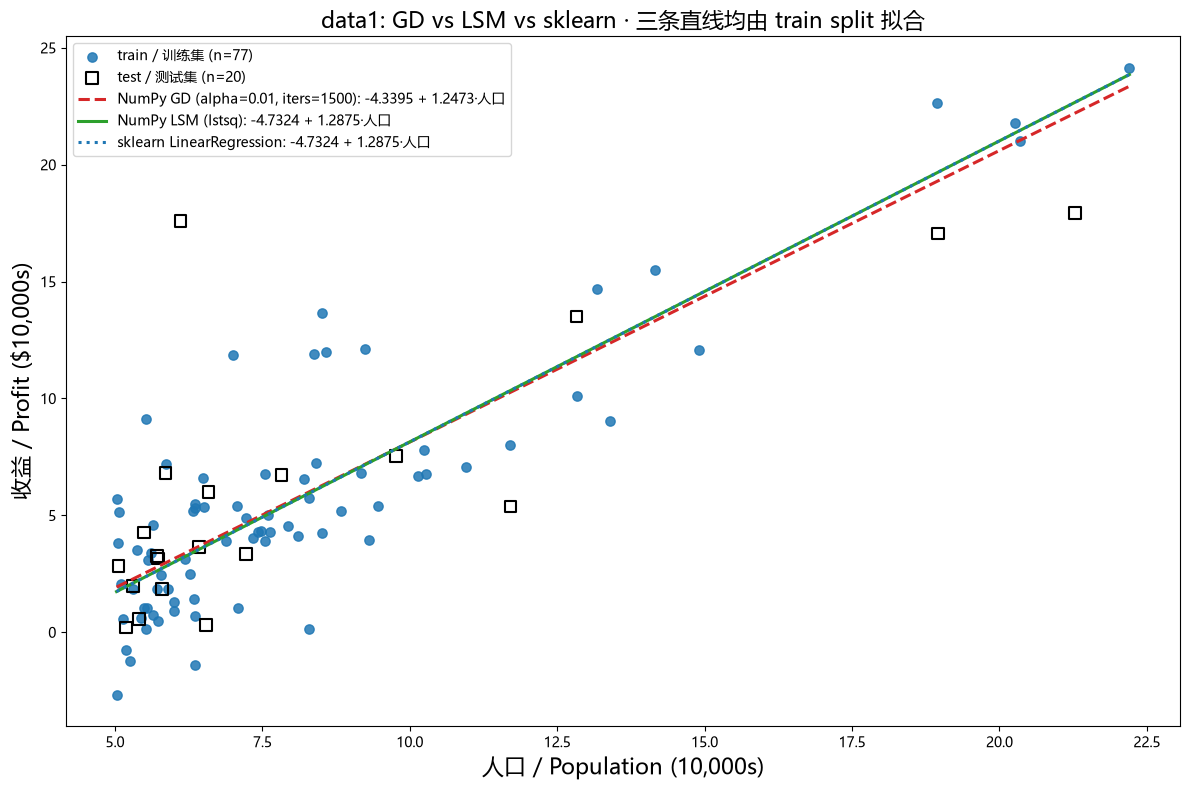

In [46]:
# ---------- 4.5 对照图：观测点 + 三条拟合直线 ----------
fig, ax = plt.subplots(figsize=(12, 8))
ax.scatter(x_train, y_train_true, s=45, alpha=0.85, label=f"train / 训练集 (n={len(x_train)})")
ax.scatter(x_test, y_test_true, s=70, marker="s", facecolor="none", edgecolor="black",
           linewidths=1.5, label=f"test / 测试集 (n={len(x_test)})")

grid = np.linspace(x1_values.min(), x1_values.max(), 100)
styles = [("--", "tab:red"), ("-", "tab:green"), (":", "tab:blue")]
for (name, w), (style, colour) in zip(split_fits.items(), styles):
    ax.plot(grid, w[0] + w[1] * grid, style, color=colour, linewidth=2.2,
            label=f"{name}: {w[0]:.4f} + {w[1]:.4f}·{FEATURES_1[0]}")

ax.set_xlabel("人口 / Population (10,000s)", fontsize=16)
ax.set_ylabel("收益 / Profit ($10,000s)", fontsize=16)
ax.set_title("data1: GD vs LSM vs sklearn · 三条直线均由 train split 拟合", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()

comparison_fig_path = FIG_DIR / "model_comparison_data1_lines.png"
fig.savefig(comparison_fig_path, dpi=150, bbox_inches="tight")
print("saved:", comparison_fig_path)
plt.show()

### 4.6 结果解读 / Interpretation (Step 06)

**NumPy 手写实现 vs scikit-learn**

- 数值上：闭式解（LSM / sklearn）解的是同一个最小化问题，参数差在机器精度量级
  （见 4.4 的输出与第 5 节的 `sklearn ↔ NumPy LSM` 校验）。差异只在**存放位置**：
  手写实现把截距放在 `w[0]`（设计矩阵第一列 1），sklearn 放在 `intercept_`。
- 工程上：手写版本把每一步都摊开（设计矩阵、代价、梯度），适合理解算法、也方便改代价函数；
  sklearn 版本省掉这些样板代码，自带 `predict`/`score`、与 `Pipeline`、交叉验证无缝衔接，
  适合真实建模。**教学用手写，实用用 sklearn。**

**梯度下降 vs 最小二乘**

- 最小二乘是闭式解：一次求解就是最优，没有学习率/迭代次数的取舍，代价是需要
  `lstsq`/SVD，特征非常多时求解成本上升。
- 梯度下降是迭代解：每轮只看梯度，内存友好、可扩展到大规模数据，但结果依赖
  `alpha` 与迭代次数——本例 GD 与闭式解的差距正是“还没收敛”，不是算法错误。
- 特征量纲差异大时（如第 3 节的房价数据），GD 收敛会明显变慢，闭式解不受影响；
  这也是后面要用标准化 / `Pipeline` 的原因。

**训练指标 vs 测试指标**

- TRAIN MSE / $R^2$ 是在拟合用过的行上算的，**天生偏乐观**（本例 Test MSE 高于 Train MSE）。
- TEST MSE / $R^2$ 才是对新数据的估计；本例测试集只有约 20 行，数值波动较大，
  因此第 7 节改用交叉验证 + `Pipeline` 来做更稳定的参数选择。
- 报告里引用任何分数时，必须同时写出**数据集、模型、以及 TRAIN / VALIDATION / TEST 范围**。

## 5. Ridge 参数选择与防泄漏验证 / Ridge & leakage-safe validation (Step 07)

这一节做三件事：

1. 在**多变量**数据 `regress_data2.csv`（`面积 + 房间数 → 价格`）上扫描 `Ridge` 的 `alpha`，
   并与普通 `LinearRegression` 基线在**同样的折、同样的指标、同样的 seed**下对比。
2. 用数字演示“**先标准化再交叉验证**”与“**标准化放进 Pipeline**”的差别，说明为什么后者才对。
3. 展示 `alpha` 变大时系数如何被收缩，以及为什么截距不受影响。

术语约定（FR-08）：

- **VALIDATION**：交叉验证折上算出来的分数，用来**选模型/选超参数**。
- **TEST**：第 4 节 `train_test_split` 留出的那 20 行，只在超参数定完之后**用一次**。
- 本节绝大部分数字是 VALIDATION；只有在“α 选择只用训练集”的流程里才会出现 TEST 分数。

In [47]:
# ---------- 5.1 多变量 data2 的 α 扫描（预处理在 Pipeline 内） ----------
rmse_mean_2, rmse_std_2 = [], []
for alpha in alphas:
    fold_rmse = np.sqrt(-cross_val_score(ridge_pipeline(alpha), X2_raw, y2_raw, cv=CV_FOLDS,
                                         scoring="neg_mean_squared_error"))
    rmse_mean_2.append(fold_rmse.mean())
    rmse_std_2.append(fold_rmse.std())

rmse_mean_2, rmse_std_2 = np.array(rmse_mean_2), np.array(rmse_std_2)
best_idx_2 = int(np.argmin(rmse_mean_2))
best_alpha_2 = float(alphas[best_idx_2])

# 基线：普通最小二乘放进同样的 Pipeline（同样的 scaler、同样的折、同样的指标）
baseline_pipe = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
baseline_rmse = np.sqrt(-cross_val_score(baseline_pipe, X2_raw, y2_raw, cv=CV_FOLDS,
                                         scoring="neg_mean_squared_error"))

sweep_data2 = pd.DataFrame({
    "alpha": alphas,
    "mean_rmse": rmse_mean_2,
    "std_rmse": rmse_std_2,
}).round(6)

print(f"data2 (regress_data2.csv) · {FEATURES_2} -> {TARGET_2} · "
      f"KFold(5, shuffle=True, random_state={RANDOM_STATE}) · VALIDATION RMSE")
print(f"  LinearRegression baseline : CV RMSE = {baseline_rmse.mean():,.2f} ± {baseline_rmse.std():,.2f}")
print(f"  best Ridge alpha          : {best_alpha_2:.4g}")
print(f"  best Ridge CV RMSE        : {rmse_mean_2[best_idx_2]:,.2f} ± {rmse_std_2[best_idx_2]:,.2f}")

sweep_path = RESULT_DIR / "ridge_alpha_sweep_data2.csv"
sweep_data2.to_csv(sweep_path, index=False, encoding="utf-8-sig")
print("saved:", sweep_path)
sweep_data2.head(10)

if best_idx_2 in (0, len(alphas) - 1):
    print("  NOTE: 最优 alpha 落在扫描区间端点 -> 在这份数据上正则化几乎没有收益"
          "（47 行、2 个特征、特征与目标相关性强），CV 曲线几乎是平的。"
          "这本身是一个结论，不是扫描写错了。")

data2 (regress_data2.csv) · ['面积', '房间数'] -> 价格 · KFold(5, shuffle=True, random_state=42) · VALIDATION RMSE
  LinearRegression baseline : CV RMSE = 67,420.22 ± 14,337.76
  best Ridge alpha          : 0.001
  best Ridge CV RMSE        : 67,420.34 ± 14,337.23
saved: D:\WIT\6th semester\AI\Linear regression\outputs\results\ridge_alpha_sweep_data2.csv
  NOTE: 最优 alpha 落在扫描区间端点 -> 在这份数据上正则化几乎没有收益（47 行、2 个特征、特征与目标相关性强），CV 曲线几乎是平的。这本身是一个结论，不是扫描写错了。


saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\ridge_alpha_sweep_data2.png


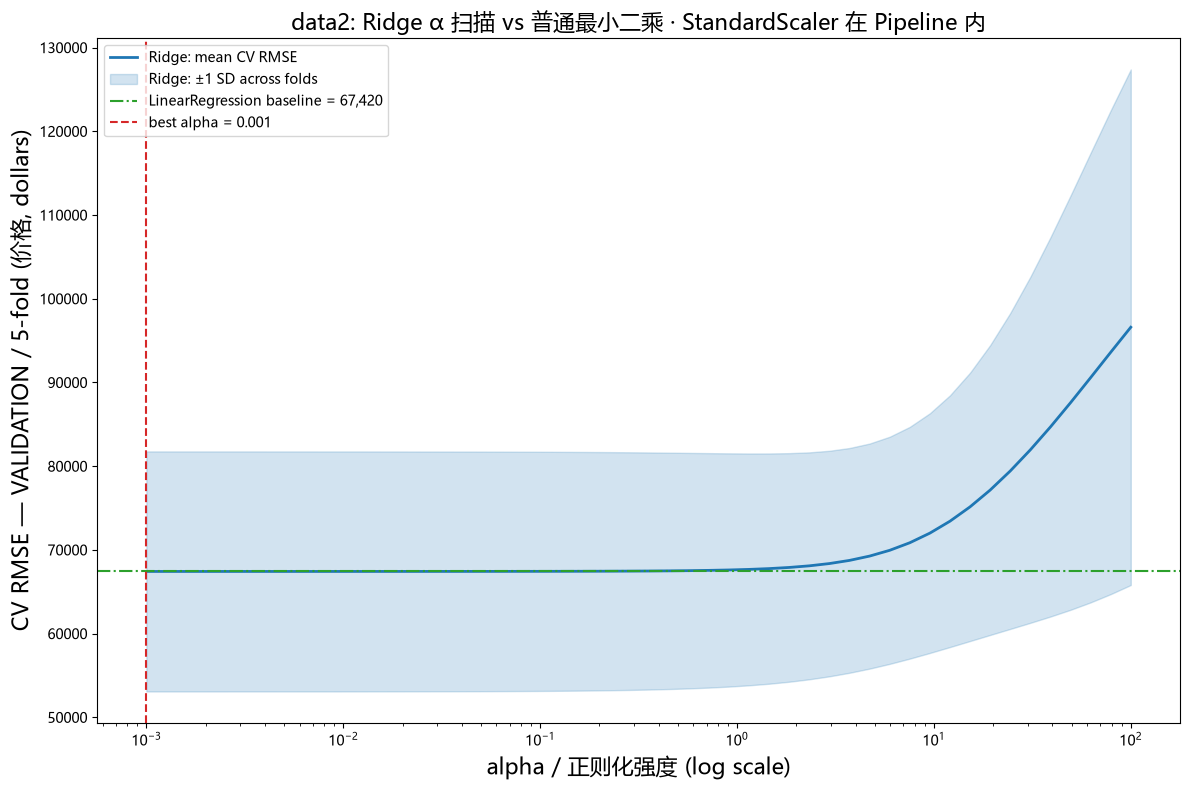

In [48]:
# ---------- 5.2 α vs CV RMSE（对数横轴 + 基线） ----------
fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(alphas, rmse_mean_2, color="tab:blue", linewidth=2, label="Ridge: mean CV RMSE")
ax.fill_between(alphas, rmse_mean_2 - rmse_std_2, rmse_mean_2 + rmse_std_2,
                color="tab:blue", alpha=0.2, label="Ridge: ±1 SD across folds")
ax.axhline(baseline_rmse.mean(), color="tab:green", linestyle="-.",
           label=f"LinearRegression baseline = {baseline_rmse.mean():,.0f}")
ax.axvline(best_alpha_2, color="tab:red", linestyle="--", label=f"best alpha = {best_alpha_2:.4g}")
ax.set_xscale("log")
ax.set_xlabel("alpha / 正则化强度 (log scale)", fontsize=16)
ax.set_ylabel("CV RMSE — VALIDATION / 5-fold (价格, dollars)", fontsize=16)
ax.set_title("data2: Ridge α 扫描 vs 普通最小二乘 · StandardScaler 在 Pipeline 内", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()

ridge_fig_2 = FIG_DIR / "ridge_alpha_sweep_data2.png"
fig.savefig(ridge_fig_2, dpi=150, bbox_inches="tight")
print("saved:", ridge_fig_2)
plt.show()

### 5.3 泄漏对照实验 / What leakage looks like

**错误做法**：先在全量 `X` 上 `StandardScaler().fit_transform(...)`，再把结果交给 `cross_val_score`。
这样每一折的“验证部分”都参与了均值和标准差的计算，验证分数会偏乐观。

**正确做法**：把 scaler 放进 `Pipeline`，`cross_val_score` 每次只在训练折上 `fit` 它。

In [49]:
# ---------- 5.3 泄漏 vs 防泄漏：同一个 alpha、同一批折 ----------
X2_scaled_all = StandardScaler().fit_transform(X2_raw)          # (a) 泄漏：scaler 看过全部 47 行
leaky_rmse = np.sqrt(-cross_val_score(Ridge(alpha=best_alpha_2), X2_scaled_all, y2_raw,
                                      cv=CV_FOLDS, scoring="neg_mean_squared_error"))
safe_rmse = np.sqrt(-cross_val_score(ridge_pipeline(best_alpha_2), X2_raw, y2_raw,
                                     cv=CV_FOLDS, scoring="neg_mean_squared_error"))

print(f"data2 · Ridge(alpha={best_alpha_2:.4g}) · 同一批 5 折 · VALIDATION RMSE")
print(f"  (a) 先标准化再 CV（泄漏）  : mean = {leaky_rmse.mean():,.2f}  ± {leaky_rmse.std():,.2f}")
print(f"  (b) scaler 放进 Pipeline   : mean = {safe_rmse.mean():,.2f}  ± {safe_rmse.std():,.2f}")
print(f"  difference (leaky - safe)  : {leaky_rmse.mean() - safe_rmse.mean():+,.2f}")
print("\n  本例差距很小：只有 2 个特征、47 行、且没有异常值，标准化统计量在折之间很稳定。")
print("  但这是**原则**不是运气——样本更小、特征更多、分布更偏时，泄漏会让验证分数系统性偏乐观，")
print("  用这种分数选出来的超参数并不可信。正确写法（Pipeline）与代价相同，所以一律用它。")

data2 · Ridge(alpha=0.001) · 同一批 5 折 · VALIDATION RMSE
  (a) 先标准化再 CV（泄漏）  : mean = 67,420.42  ± 14,337.14
  (b) scaler 放进 Pipeline   : mean = 67,420.34  ± 14,337.23
  difference (leaky - safe)  : +0.08

  本例差距很小：只有 2 个特征、47 行、且没有异常值，标准化统计量在折之间很稳定。
  但这是**原则**不是运气——样本更小、特征更多、分布更偏时，泄漏会让验证分数系统性偏乐观，
  用这种分数选出来的超参数并不可信。正确写法（Pipeline）与代价相同，所以一律用它。


### 5.4 完整流程示范：α 只在训练集上选，测试集只评分一次 / Honest workflow (data1)

第 4 节已经把 data1 切成 train/test。这里按正确顺序再来一遍：
**在 train 上做 CV 选 α → 用选中的 α 在 train 上重新拟合 → 只在 test 上给一次 TEST 分数**。

In [50]:
# ---------- 5.4 data1：CV(在 train 内) 选 α -> test 只评分一次 ----------
inner_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

selection_rmse = []
for alpha in alphas:
    fold_rmse = np.sqrt(-cross_val_score(ridge_pipeline(alpha), X1_train, y1_train, cv=inner_cv,
                                         scoring="neg_mean_squared_error"))
    selection_rmse.append(fold_rmse.mean())
selection_rmse = np.array(selection_rmse)
best_alpha_train = float(alphas[int(np.argmin(selection_rmse))])

final_ridge = ridge_pipeline(best_alpha_train).fit(X1_train, y1_train)     # refit on the train split
final_ols = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())]).fit(X1_train, y1_train)

print(f"data1 · α 由 train split 内的 5 折 CV 选出 = {best_alpha_train:.4g} "
      f"(VALIDATION RMSE = {selection_rmse.min():.4f})")

rows = []
for label, model in [(f"Ridge(alpha={best_alpha_train:.4g})", final_ridge), ("LinearRegression", final_ols)]:
    train_rmse = float(np.sqrt(mean_squared_error(y_train_true, model.predict(X1_train))))
    test_rmse = float(np.sqrt(mean_squared_error(y_test_true, model.predict(X1_test))))
    rows.append({"model": label, "Train RMSE": round(train_rmse, 4), "TEST RMSE": round(test_rmse, 4)})

holdout_table = pd.DataFrame(rows).set_index("model")
print("\nVALIDATION 用来选 α，下面的 TEST 列只在上一步定好 α 之后算一次：")
holdout_table

data1 · α 由 train split 内的 5 折 CV 选出 = 0.001 (VALIDATION RMSE = 2.6882)

VALIDATION 用来选 α，下面的 TEST 列只在上一步定好 α 之后算一次：


,Train RMSE,TEST RMSE
model,,
Ridge(alpha=0.001),2.715,3.9635
LinearRegression,2.715,3.9635


### 5.5 `alpha` 如何改变模型 / Coefficient shrinkage

In [51]:
# ---------- 5.5 系数收缩：alpha 越大，系数越接近 0（截距不受影响） ----------
print(f"data2 · Ridge · 系数在标准化单位下（$ / 1 SD）· TRAINING fit on all 47 rows")
print(f"  {'alpha':>12}{'intercept':>16}{'面积':>16}{'房间数':>16}{'|w| (不含截距)':>18}")
for alpha in [1e-3, 1.0, 1e1, 1e2, 1e3, 1e4]:
    pipe = ridge_pipeline(alpha).fit(X2_raw, y2_raw)
    model = pipe.named_steps["model"]
    weights = np.asarray(model.coef_, dtype=float)
    print(f"  {alpha:>12.0e}{float(model.intercept_):>16,.1f}"
          f"{weights[0]:>16,.1f}{weights[1]:>16,.1f}{np.linalg.norm(weights):>18,.1f}")

print("\n  读法：alpha 增大 -> 系数向量的模 |w| 单调下降（这才是'收缩'的准确说法）；")
print("        单个系数不一定单调变小——面积与房间数相关时，惩罚会把权重在两者之间重新分配，")
print("        所以 房间数 的系数会先变号、再一起被压向 0（alpha 足够大时两者都趋于 0）。")
print("        截距那一列始终不动：Ridge 不惩罚自己的 intercept_，我们也没有手动塞一列 1 进去。")

data2 · Ridge · 系数在标准化单位下（$ / 1 SD）· TRAINING fit on all 47 rows
         alpha       intercept              面积             房间数        |w| (不含截距)
         1e-03       340,412.7       109,444.3        -6,576.3         109,641.7
         1e+00       340,412.7       106,080.0        -4,594.8         106,179.5
         1e+01       340,412.7        84,366.4         6,156.5          84,590.7
         1e+02       340,412.7        31,700.2        11,816.4          33,830.9
         1e+03       340,412.7         4,689.0         2,338.0           5,239.6
         1e+04       340,412.7           494.1           254.6             555.9

  读法：alpha 增大 -> 系数向量的模 |w| 单调下降（这才是'收缩'的准确说法）；
        单个系数不一定单调变小——面积与房间数相关时，惩罚会把权重在两者之间重新分配，
        所以 房间数 的系数会先变号、再一起被压向 0（alpha 足够大时两者都趋于 0）。
        截距那一列始终不动：Ridge 不惩罚自己的 intercept_，我们也没有手动塞一列 1 进去。


### 5.6 结果解读 / Interpretation (Step 07)

**为什么需要正则化**：普通最小二乘在特征相关或小样本时方差很大——换一批数据，系数会跳很多。
`Ridge` 在代价里加一项 $\lambda\sum_j w_j^2$，用**一点偏差换更小的方差**。

**`alpha` 的作用**：

- `alpha → 0`：几乎退化为普通最小二乘（系数不被收缩）。
- `alpha` 增大：系数**向量的模** $|\mathbf{w}|$ 被单调压小（见 5.5 的输出），模型变简单、
  对训练样本的波动不再敏感（方差下降、偏差上升）。单个系数不一定单调变小——
  `面积` 与 `房间数` 相关时，惩罚会在两者之间重新分配权重（5.5 里 `房间数` 的系数先变号）。
- `alpha → ∞`：所有系数趋于 0，模型退化为“永远预测均值”，此时偏差最大、方差最小。
  因此扫描曲线通常先降后升，最低点就是**偏差-方差权衡**最合适的位置（见 5.2 图）。
- **截距不参与正则化**：`Ridge` 不惩罚自己的 `intercept_`；我们也没有手动加一列 1，
  所以不存在“同一个截距被两套规则对待”的问题。

**为什么必须先标准化再正则化**：惩罚项对**所有系数一视同仁**，如果特征量纲差很多
（`面积` 约 10²–10³，`房间数` 是 1–5），不标准化就等于只惩罚量纲小的那个特征。
这就是要把 `StandardScaler` 放进 `Pipeline` 的原因——顺便也保证了它只看到训练折。

**泄漏为什么重要**：验证分数的意义是“模拟没见过的数据”。如果 scaler（甚至任何
从数据里学出来的东西：缺失值填充、特征选择、降维）在切分**之前**就 fit 过全量数据，
验证折的信息已经进了模型，分数就会偏乐观，用它选出来的 `alpha` 也不可信。
5.3 的实验在本数据上差距很小，但正确写法（Pipeline）零额外成本，所以一律采用。

**VALIDATION vs TEST**：本节所有“CV RMSE”都是 VALIDATION 分数（用来选 α）；
只有 5.4 的 `TEST RMSE` 是在 α 定完之后、对 20 行留出集算的一次性评估。
两者不能互相替代，也不能把 VALIDATION 分数当作最终成绩写进报告。

## 6. 图表规范与结果解读 / Figures and interpretation (Step 08)

这一节统一图表风格并把**报告要用到的六张图**集中产出，每张图下面都配一段解读
（数据集 / 模型 / 看到了什么 / 报告能写什么结论）。

**字体与可移植性 / Font fallback**

- 第 0 节的设置单元按 `[SimHei, Microsoft YaHei, Noto Sans CJK SC, Arial Unicode MS]` 顺序查找，
  找不到 CJK 字体时回落到 `DejaVu Sans`，**不会因为缺字体而让 kernel 报错**。
- 因此所有坐标轴标题都写成双语：`人口 / Population (10,000s)`、`价格 / Price (USD)`。
  在缺字体的机器上中文会显示成方框，但英文部分仍然可读，图放进报告不会变成一堆乱码。
- 当前环境实际使用的字体由下面单元打印。

In [52]:
# ---------- 6.0 图表 house style ----------
FIGSIZE = (12, 8)          # 全 notebook 统一尺寸
DPI = 150


def save_fig(name, fig=None, dpi=DPI):
    """Save the current (or given) figure to outputs/figures/ with the project's house style."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name
    (fig if fig is not None else plt.gcf()).savefig(path, dpi=dpi, bbox_inches="tight")
    print("saved:", path)
    return path


print("matplotlib font stack:", plt.rcParams["font.sans-serif"][:3], "...")
print("CJK font in use      :", selected_fonts[0] if selected_fonts else "none -> English gloss only")

matplotlib font stack: ['Microsoft YaHei', 'DejaVu Sans'] ...
CJK font in use      : Microsoft YaHei


### 图 a · data1 散点 + 最终拟合直线 / Final fitted line

**数据集** `regress_data1.csv`（97 行）；**模型** scikit-learn `LinearRegression`
（与第 5 节闭式解完全相同的参数）。

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_a_data1_final_fitted_line.png


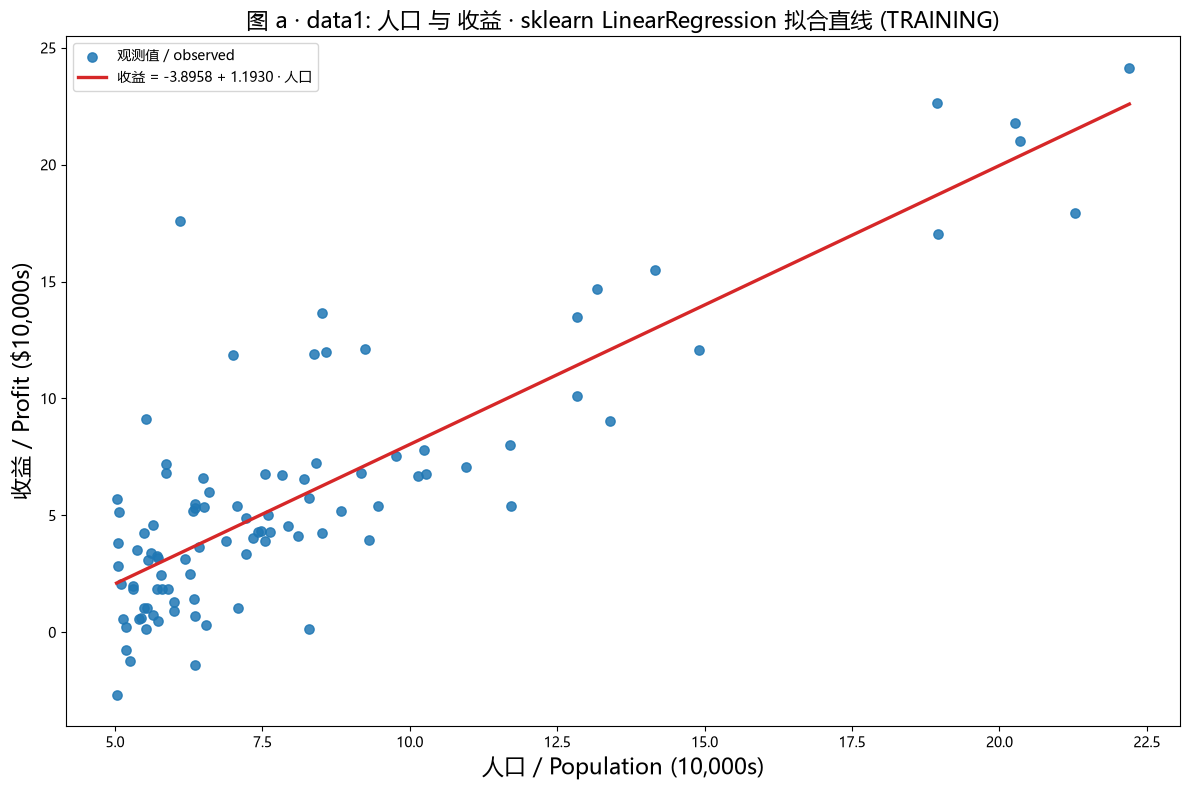

In [53]:
# ---------- 图 a：data1 观测值 + 最终模型直线 ----------
w_final_1 = w_to_array(sk_model_1)          # == NumPy LSM 的参数（差 ~1e-15）

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.scatter(X1_raw[FEATURES_1[0]], y1_raw, s=45, alpha=0.85, label="观测值 / observed")
grid_1 = np.linspace(x1_values.min(), x1_values.max(), 200)
ax.plot(grid_1, w_final_1[0] + w_final_1[1] * grid_1, color="tab:red", linewidth=2.4,
        label=f"{TARGET_1} = {w_final_1[0]:.4f} + {w_final_1[1]:.4f} · {FEATURES_1[0]}")
ax.set_xlabel("人口 / Population (10,000s)", fontsize=16)
ax.set_ylabel("收益 / Profit ($10,000s)", fontsize=16)
ax.set_title("图 a · data1: 人口 与 收益 · sklearn LinearRegression 拟合直线 (TRAINING)", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()
save_fig("fig_a_data1_final_fitted_line.png")
plt.show()

**解读（图 a）：** 人口越多、收益越高，散点云呈明显的**正相关**上升带（相关系数约 0.838，见第 1 节），
直线穿过点云中部，两端没有系统性偏离。报告可以写：一元线性模型抓住了主要趋势；
但点云在直线上下有明显散布（$R^2\approx 0.70$），说明人口之外还有其它因素影响收益。

### 图 b · 梯度下降训练代价曲线 / Training cost history

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_b_data1_gd_cost_history.png


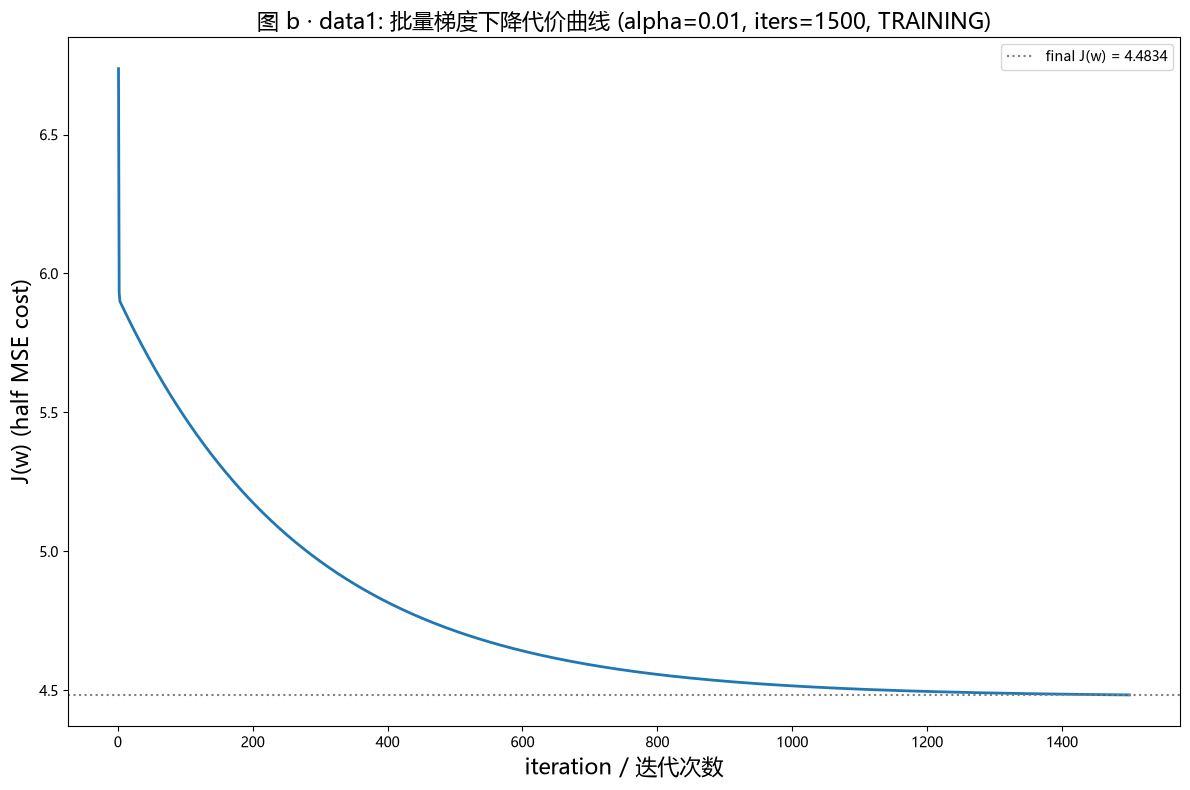

In [54]:
# ---------- 图 b：J(w) 随迭代下降 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(np.arange(1, len(cost_history1) + 1), cost_history1, color="tab:blue", linewidth=2)
ax.axhline(cost_history1[-1], color="tab:gray", linestyle=":",
           label=f"final J(w) = {cost_history1[-1]:.4f}")
ax.set_xlabel("iteration / 迭代次数", fontsize=16)
ax.set_ylabel("J(w) (half MSE cost)", fontsize=16)
ax.set_title(f"图 b · data1: 批量梯度下降代价曲线 (alpha={ALPHA_GD}, iters={ITERS_GD}, TRAINING)", fontsize=16)
ax.legend(loc=1)
fig.tight_layout()
save_fig("fig_b_data1_gd_cost_history.png")
plt.show()

**解读（图 b）：** 代价从 $J\approx 32.07$ 单调下降到 $J\approx 4.48$（第 2 节的收敛性检查确认单调），
前几百轮下降最快、之后趋于平缓——这正是固定学习率梯度下降的典型形状，也说明
**1500 轮还没完全收敛**（与闭式解的参数差 ~0.27，见 4.4）。报告可以据此讨论"迭代次数/学习率"的取舍。

### 图 c · 三种实现的拟合直线对照 / Three fits in one axes

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_c_data1_three_fits.png


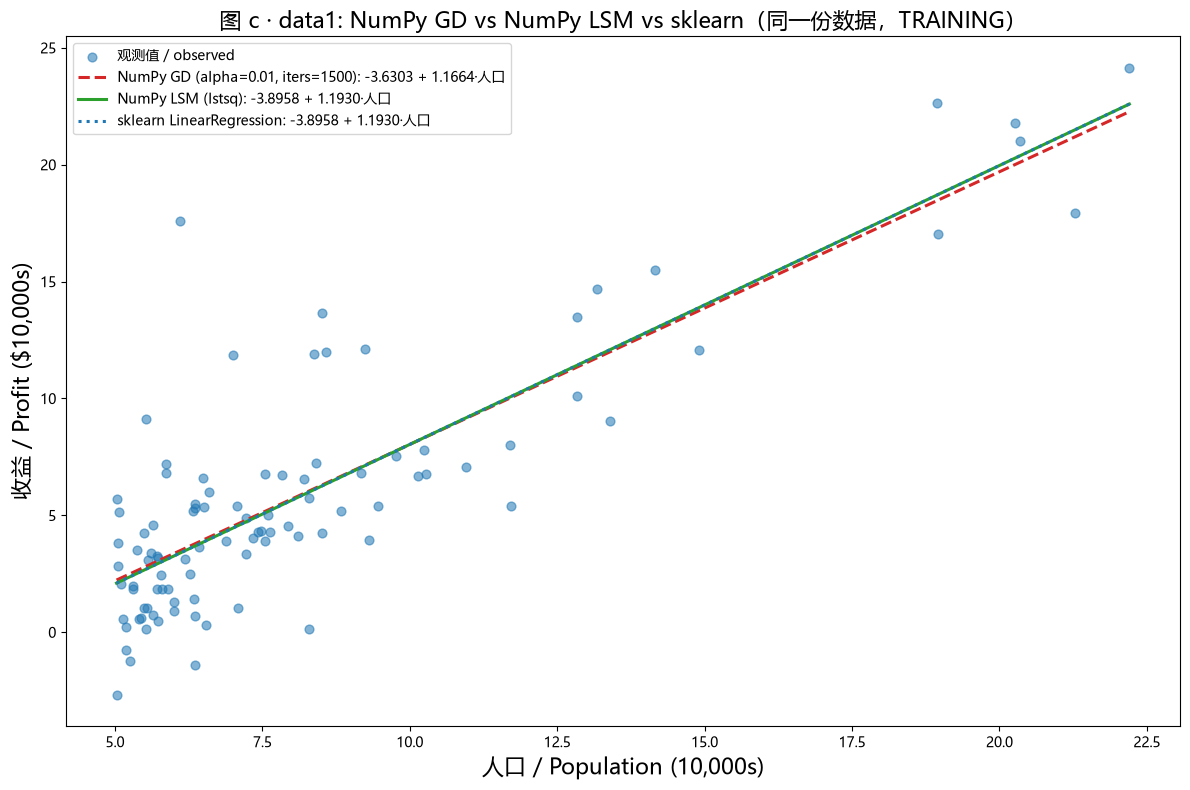

In [55]:
# ---------- 图 c：GD / LSM / sklearn 三条线（同一份 data1） ----------
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.scatter(X1_raw[FEATURES_1[0]], y1_raw, s=40, alpha=0.55, label="观测值 / observed")
styles = [("--", "tab:red"), ("-", "tab:green"), (":", "tab:blue")]
for (name, w), (style, colour) in zip(full_fits.items(), styles):
    ax.plot(grid_1, w[0] + w[1] * grid_1, style, color=colour, linewidth=2.2,
            label=f"{name}: {w[0]:.4f} + {w[1]:.4f}·{FEATURES_1[0]}")
ax.set_xlabel("人口 / Population (10,000s)", fontsize=16)
ax.set_ylabel("收益 / Profit ($10,000s)", fontsize=16)
ax.set_title("图 c · data1: NumPy GD vs NumPy LSM vs sklearn（同一份数据，TRAINING）", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()
save_fig("fig_c_data1_three_fits.png")
plt.show()

**解读（图 c）：** LSM（绿实线）与 sklearn（蓝点线）完全重合——它们解的是同一个最小二乘问题；
GD（红虚线）略微偏低，是**迭代尚未收敛**造成的，不是算法不同。三者在点云密集区几乎无法区分，
说明这种量级的参数差对预测影响很小，但在报告里必须说清"为什么差"。

### 图 d · 训练 vs 测试 MSE / Train vs test bars

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_d_data1_train_test_mse.png


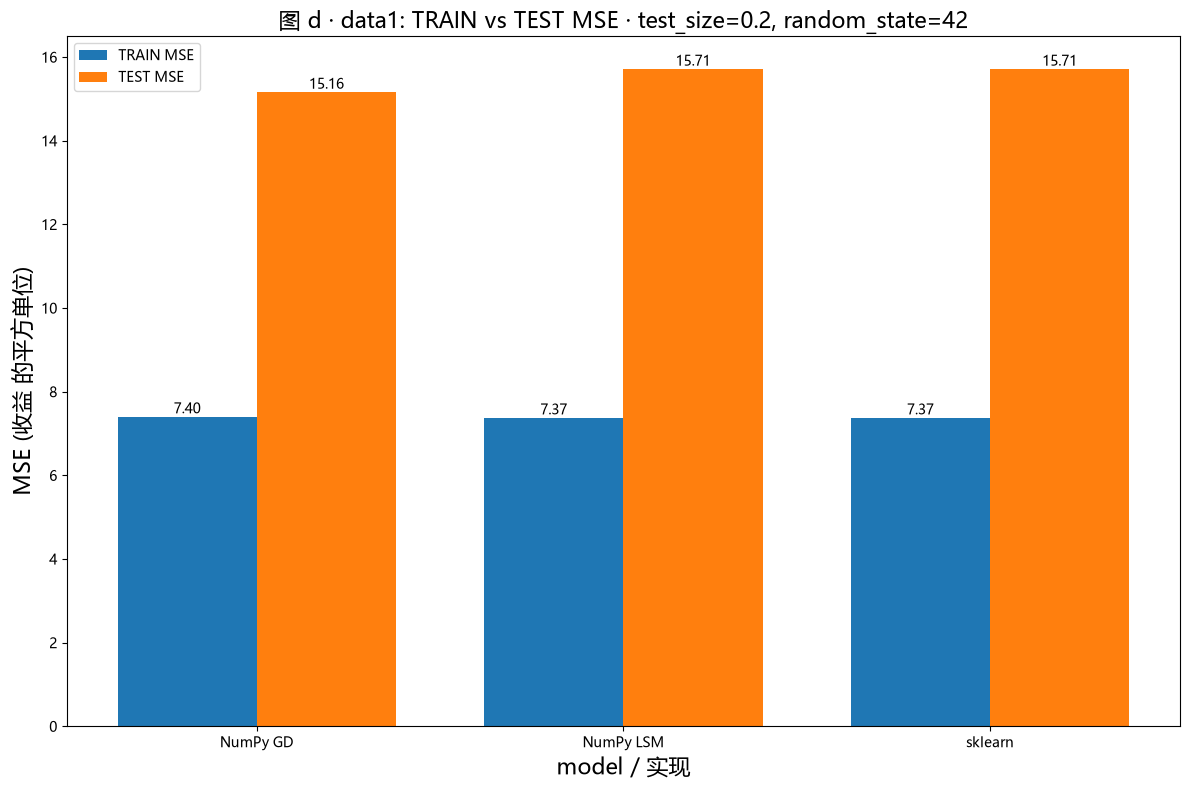

In [56]:
# ---------- 图 d：Step 06 汇总表的 Train/Test MSE 柱状图 ----------
short_labels = ["NumPy GD", "NumPy LSM", "sklearn"]
positions = np.arange(len(comparison_data1))
width = 0.38

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(positions - width / 2, comparison_data1["Train MSE"], width, color="tab:blue", label="TRAIN MSE")
ax.bar(positions + width / 2, comparison_data1["Test MSE"], width, color="tab:orange", label="TEST MSE")
for i, (train_mse, test_mse) in enumerate(zip(comparison_data1["Train MSE"], comparison_data1["Test MSE"])):
    ax.text(i - width / 2, train_mse, f"{train_mse:.2f}", ha="center", va="bottom", fontsize=10)
    ax.text(i + width / 2, test_mse, f"{test_mse:.2f}", ha="center", va="bottom", fontsize=10)
ax.set_xticks(positions)
ax.set_xticklabels(short_labels)
ax.set_xlabel("model / 实现", fontsize=16)
ax.set_ylabel(f"MSE ({TARGET_1} 的平方单位)", fontsize=16)
ax.set_title(f"图 d · data1: TRAIN vs TEST MSE · test_size=0.2, random_state={RANDOM_STATE}", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()
save_fig("fig_d_data1_train_test_mse.png")
plt.show()

**解读（图 d）：** 三个实现的柱子高度几乎相同（参数差异在预测上被抹平），但**橙色（TEST）一律高于蓝色（TRAIN）**——
这是本实验最重要的方法论结论：训练误差天生乐观，只有留出集/交叉验证才是可信的泛化估计。
测试集只有 20 行，因此 TEST 柱子的高度对切分很敏感（这也是第 5 节改用 5 折 CV 的原因）。

### 图 e · Ridge α 扫描（多变量 data2）/ Alpha vs CV RMSE

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_e_data2_ridge_alpha_cv_rmse.png


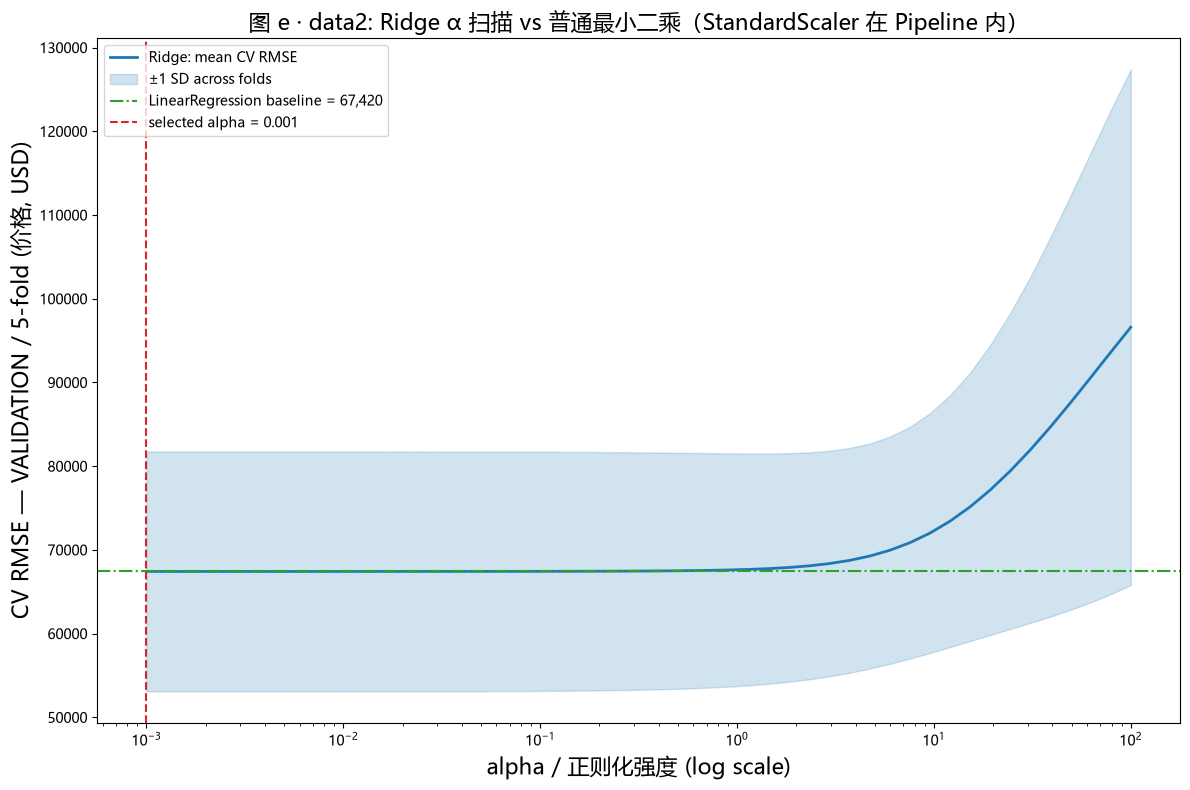

In [57]:
# ---------- 图 e：α 扫描（与 5.2 同一组数字，统一风格另存一份） ----------
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.plot(alphas, rmse_mean_2, color="tab:blue", linewidth=2, label="Ridge: mean CV RMSE")
ax.fill_between(alphas, rmse_mean_2 - rmse_std_2, rmse_mean_2 + rmse_std_2,
                color="tab:blue", alpha=0.2, label="±1 SD across folds")
ax.axhline(baseline_rmse.mean(), color="tab:green", linestyle="-.",
           label=f"LinearRegression baseline = {baseline_rmse.mean():,.0f}")
ax.axvline(best_alpha_2, color="tab:red", linestyle="--", label=f"selected alpha = {best_alpha_2:.4g}")
ax.set_xscale("log")
ax.set_xlabel("alpha / 正则化强度 (log scale)", fontsize=16)
ax.set_ylabel("CV RMSE — VALIDATION / 5-fold (价格, USD)", fontsize=16)
ax.set_title("图 e · data2: Ridge α 扫描 vs 普通最小二乘（StandardScaler 在 Pipeline 内）", fontsize=16)
ax.legend(loc=2)
fig.tight_layout()
save_fig("fig_e_data2_ridge_alpha_cv_rmse.png")
plt.show()

**解读（图 e）：** 曲线在 $\alpha$ 很小时几乎是平的，最优值落在扫描区间左端（$\alpha=10^{-3}$），
与普通最小二乘基线（绿点划线）几乎重合 —— 说明**在这份 47 行、2 特征的数据上正则化没有带来收益**；
$\alpha$ 继续增大时 CV RMSE 上升，体现"过度收缩 → 偏差过大"的一面。报告应当如实写这个结论，
而不是假装 Ridge 一定更好。折间标准差（浅蓝带）很大，说明小样本下 CV 分数本身不稳定。

### 图 f · 多变量：预测值 vs 真实值、残差图 / Predicted vs actual and residuals

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_f1_data2_pred_vs_actual.png


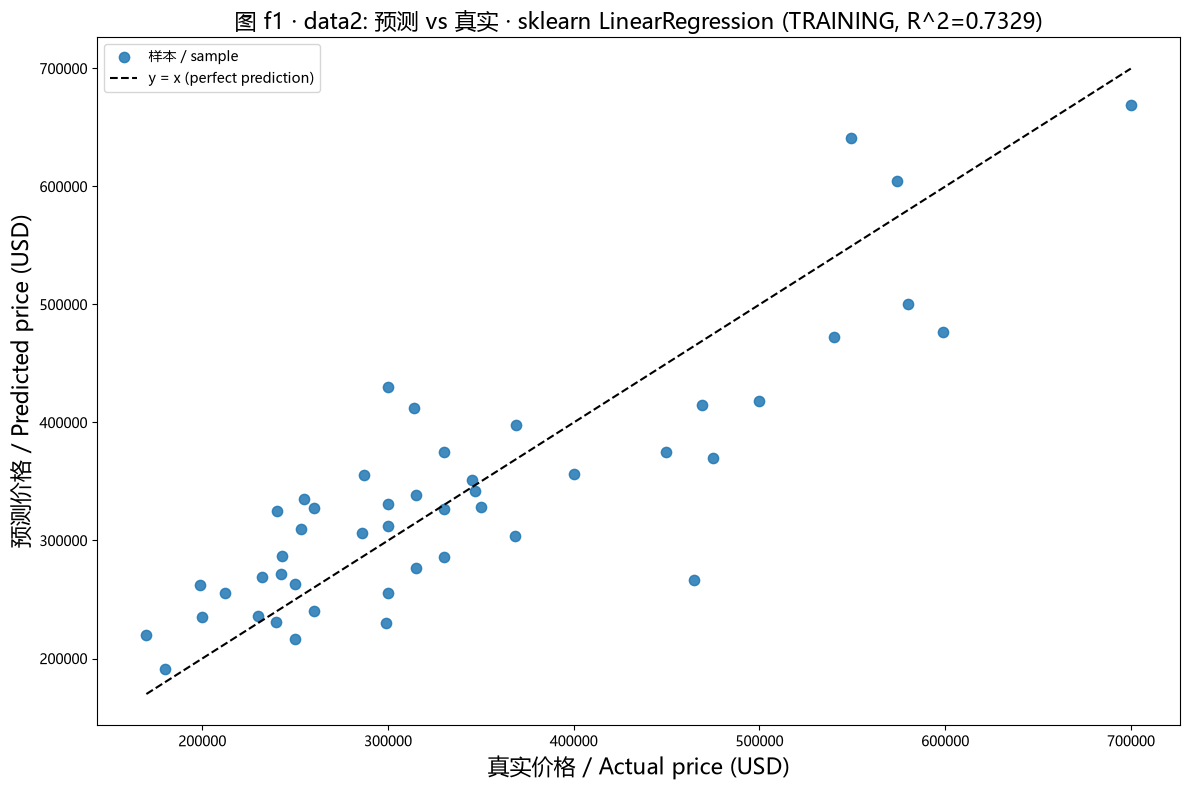

In [58]:
# ---------- 图 f1：预测值 vs 真实值（含 y=x 参考线） ----------
prediction_2 = sk_model_2.predict(X2_raw)          # TRAINING (in-sample) predictions
residual_2 = np.asarray(y2_raw, dtype=float) - prediction_2

fig, ax = plt.subplots(figsize=FIGSIZE)
ax.scatter(y2_raw, prediction_2, s=55, alpha=0.85, label="样本 / sample")
limit_2 = [float(np.min([y2_raw.min(), prediction_2.min()])), float(np.max([y2_raw.max(), prediction_2.max()]))]
ax.plot(limit_2, limit_2, "k--", linewidth=1.5, label="y = x (perfect prediction)")
ax.set_xlabel("真实价格 / Actual price (USD)", fontsize=16)
ax.set_ylabel("预测价格 / Predicted price (USD)", fontsize=16)
ax.set_title(f"图 f1 · data2: 预测 vs 真实 · sklearn LinearRegression (TRAINING, R^2={sk_model_2.score(X2_raw, y2_raw):.4f})",
             fontsize=16)
ax.legend(loc=2)
fig.tight_layout()
save_fig("fig_f1_data2_pred_vs_actual.png")
plt.show()

saved: D:\WIT\6th semester\AI\Linear regression\outputs\figures\fig_f2_data2_residuals.png


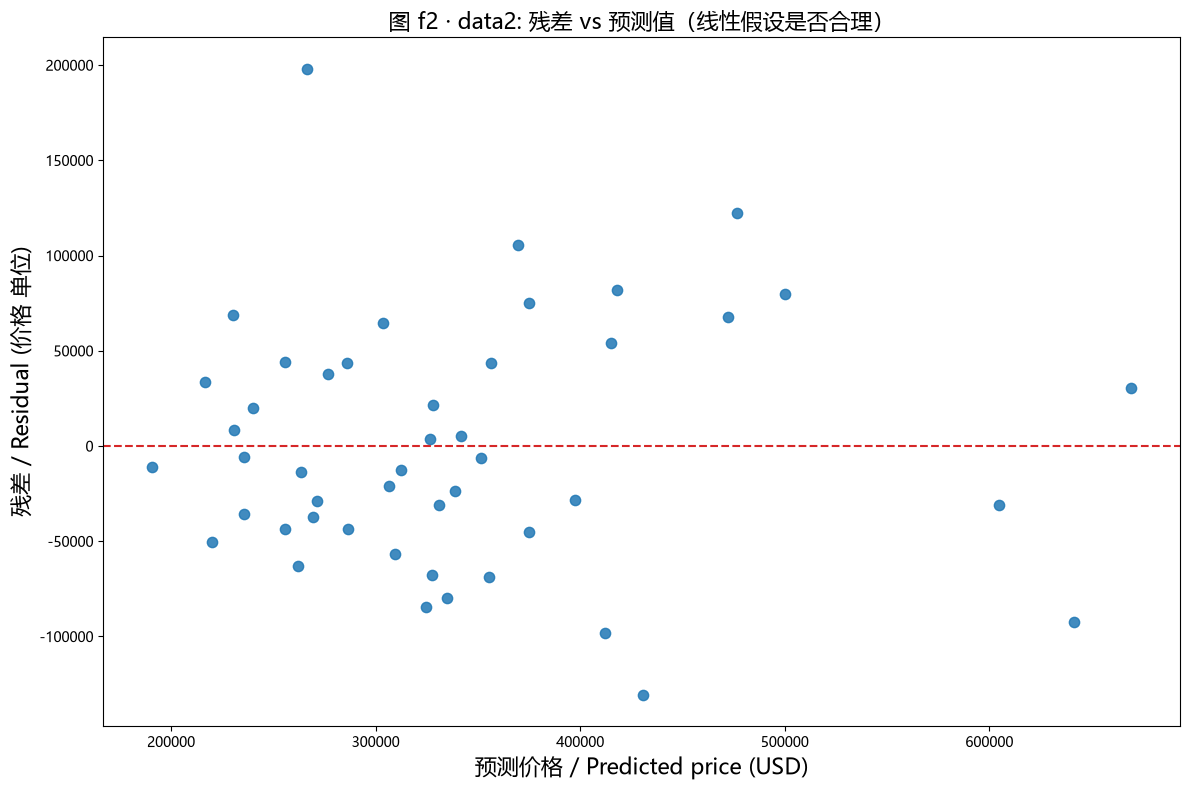

data2 · 残差检查 / residual diagnostics (TRAINING, n=47)
  mean(residual)                = 0.00   <- 含截距时必然 ≈ 0
  SD(residual)                  = 63,926.21
  SD(residual) | 低价半区       = 57,778
  SD(residual) | 高价半区       = 69,760   <- 略大：轻微方差不齐
  corr(residual, 面积^2)        = -0.007   <- ≈0：没有明显曲率


In [59]:
# ---------- 图 f2：残差 vs 预测值 + 残差分布的数值检查 ----------
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.scatter(prediction_2, residual_2, s=55, alpha=0.85)
ax.axhline(0.0, color="tab:red", linestyle="--", linewidth=1.5)
ax.set_xlabel("预测价格 / Predicted price (USD)", fontsize=16)
ax.set_ylabel(f"残差 / Residual ({TARGET_2} 单位)", fontsize=16)
ax.set_title("图 f2 · data2: 残差 vs 预测值（线性假设是否合理）", fontsize=16)
fig.tight_layout()
save_fig("fig_f2_data2_residuals.png")
plt.show()

median_prediction = float(np.median(prediction_2))
low_half = prediction_2 <= median_prediction
print(f"data2 · 残差检查 / residual diagnostics (TRAINING, n={len(residual_2)})")
print(f"  mean(residual)                = {residual_2.mean():,.2f}   <- 含截距时必然 ≈ 0")
print(f"  SD(residual)                  = {residual_2.std(ddof=0):,.2f}")
print(f"  SD(residual) | 低价半区       = {residual_2[low_half].std(ddof=0):,.0f}")
print(f"  SD(residual) | 高价半区       = {residual_2[~low_half].std(ddof=0):,.0f}   <- 略大：轻微方差不齐")
print(f"  corr(residual, 面积^2)        = {np.corrcoef(residual_2, X2_raw['面积'].to_numpy() ** 2)[0, 1]:+.3f}"
      "   <- ≈0：没有明显曲率")

**解读（图 f1 / f2）：** 点大致沿 $y=x$ 参考线分布（$R^2\approx 0.733$），高价位一端偏离更大。
残差图上点围绕 0 线散布，`corr(residual, 面积²) ≈ 0` 说明**没有明显的曲率**，
即线性形式本身没有被数据否决；但高价半区的残差标准差（约 69,760）大于低价半区（约 57,778），
呈现**轻微方差不齐**——47 行的小样本不足以据此改模型形式，报告里应写成"线性假设合理，
但残差随价格水平略有放大，若样本更大可考虑对目标取对数或加权最小二乘"。

### 定性结论汇总 / Qualitative findings (Step 08)

- **人口 → 收益：正相关。** 相关系数约 0.838，拟合斜率约 1.19（每增加 1 万人，收益约增 1.19 个万美元单位）。
- **面积 是价格的主要解释变量，房间数 很弱。** 与价格的相关性：面积 ≈ 0.855 ≫ 房间数 ≈ 0.442；
  在双特征模型里房间数的系数甚至是负的（-8,738），说明在这个小样本中它没有提供超出面积的增量信息。
- **量纲会彻底改变"系数大小"的直觉。** 原始单位下 面积 系数 139.2（每平方英尺）看起来远大于 房间数 的
  -8,738 ÷ 0.75 ≈ 每 1 个标准差；换成"每 1 个标准差"单位后是 面积 +109,448 美元 vs 房间数 -6,578 美元
  —— 系数大小**不等于**重要性，比较前必须统一量纲。
- **Ridge 的 α 越大，系数向量越短。** |w| 从 109,642（α=1e-3）单调压到 556（α=1e4），
  同时 CV RMSE 上升：过度收缩会把有用信号一起压掉。

## 7. 报告交付物 / Report deliverables (Step 09)

实验要求提交：① 算法流程图 ② 实验结果与分析图 ③ 带注释的源代码 ④ 学生独立撰写的心得总结。
下面按顺序给出 ①②③，④ 只给结构（必须自己写）。

### 7.1 算法流程图 / Flowchart — 整体流程

```mermaid
flowchart TD
    A["读取 CSV / load_csv<br/>data/regress_data1.csv, regress_data2.csv"] --> B["检查与校验 / summarize_dataset<br/>shape, 列名, 缺失值, 类型"]
    B --> C["选定特征与目标 / FEATURES_1, FEATURES_2"]
    C --> D1["NumPy 批量梯度下降<br/>computeCost + batch_gradientDescent"]
    C --> D2["NumPy 最小二乘<br/>LSM (np.linalg.lstsq)"]
    C --> D3["scikit-learn<br/>LinearRegression / Ridge"]
    D1 --> E["代价与指标<br/>J(w), MSE, R^2"]
    D2 --> E
    D3 --> E
    E --> F["对照与评估<br/>train_test_split (TEST) 与 KFold CV (VALIDATION)"]
    F --> G["参数选择<br/>Ridge alpha 扫描（Pipeline 内标准化）"]
    E --> H["图表与解读<br/>outputs/figures/"]
    G --> H
    H --> I["报告材料<br/>表格 outputs/results/ + 结论"]
```

### 7.1b 算法流程图 / Flowchart — 批量梯度下降循环

```mermaid
flowchart TD
    S(["开始 / start"]) --> I["初始化 w = 0<br/>设定 alpha, iters"]
    I --> P["用当前 w 计算预测 X @ w"]
    P --> C["计算代价 J(w) = 1/(2m) Σ(Xw - y)²"]
    C --> G["计算梯度 ∇J = Xᵀ(Xw - y) / m"]
    G --> U["同时更新所有 w_j：w ← w - alpha·∇J"]
    U --> Q{"达到 iters<br/>或代价变化很小?"}
    Q -- 否 --> P
    Q -- 是 --> E(["输出 w 与 cost_history"])
```

### 7.2 带注释的源代码附录 / Consolidated code appendix

下面用 `inspect.getsource` **直接打印正在运行的函数**，避免附录里的代码与实际执行的代码不一致。
每个函数的 docstring 说明参数、返回值与实现的公式；注释解释"为什么这样写"。

In [60]:
# ---------- 7.2 代码附录：直接取回运行中的源码（不会与正文漂移） ----------
import inspect

KEY_FUNCTIONS = {
    "load_csv": "读 data/ 下的 CSV 并校验必需列；路径由 PROJECT_ROOT 推导，与工作目录无关。",
    "summarize_dataset": "拟合前的体检：shape、列名、缺失/非数值检查，并给出特征与目标的相关系数。",
    "computeCost": "J(w) = 1/(2m)·Σ(Xw - y)²；纯函数，不改入参，兼容 ndarray 与 np.matrix。",
    "batch_gradientDescent": "真正的批量更新：每轮由同一个 w 算一个梯度，再同时更新所有 w_j。",
    "LSM": "正规方程 w* = argmin||Xw - y||²，用 lstsq(SVD) 求解；不用 inv(XᵀX)。",
}

for name, why in KEY_FUNCTIONS.items():
    function = globals()[name]
    print("=" * 88)
    print(f"{name} — {why}")
    print("=" * 88)
    print(inspect.getsource(function))

load_csv — 读 data/ 下的 CSV 并校验必需列；路径由 PROJECT_ROOT 推导，与工作目录无关。
def load_csv(filename, required_columns=None):
    """Load a CSV from DATA_DIR and check that its required columns exist.

    Raises FileNotFoundError naming the missing file, or ValueError naming the
    missing column(s).
    """
    path = DATA_DIR / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Data file not found: {path}. "
            f"Expected the working copy inside {DATA_DIR}."
        )

    df = pd.read_csv(path)

    missing = [column for column in (required_columns or []) if column not in df.columns]
    if missing:
        raise ValueError(
            f"{filename} is missing required column(s): {missing}. "
            f"Columns found: {list(df.columns)}"
        )

    print(f"Loaded {filename}: shape={df.shape}, columns={list(df.columns)}")
    return df

summarize_dataset — 拟合前的体检：shape、列名、缺失/非数值检查，并给出特征与目标的相关系数。
def summarize_dataset(df, name, features, target):
    ""

**几个"为什么"的注释（写给报告的说明）：**

- `load_csv` 校验列名而不是列号：CSV 表头是中文，列顺序一变静默出错最难查。
- `computeCost` 保持纯函数：代价函数被梯度下降每轮调用上千次，任何副作用/打印都会拖慢并污染输出。
- `batch_gradientDescent` 先算完整梯度再统一更新：如果边算边改 $w_j$，就变成坐标下降，与教材公式不一致。
- `LSM` 用 `lstsq` 而不是 `inv(XᵀX)`：后者在实际数据中常因共线或奇异矩阵失败（第 5 节有秩亏演示）。
- 所有 sklearn 调用都传**原始**特征：截距交给 `fit_intercept`，避免出现两个截距（第 3 节）。

### 7.3 结果附录 / Results appendix

下面重新显示第 4、5 节产生的两张结果表，并列出 `outputs/` 下所有可引用的产物。

In [61]:
# ---------- 7.3a 第 4 节：三种实现对照表（TRAIN / TEST） ----------
print("表 1 ·", caption)
display(comparison_data1)

表 1 · data1 (regress_data1.csv) · 人口 -> 收益 · train_test_split(test_size=0.2, random_state=42) · TRAIN = in-sample, TEST = held-out


,Intercept,Slope (人口),Train MSE,Train R^2,Test MSE,Test R^2
model,,,,,,
"NumPy GD (alpha=0.01, iters=1500)",-4.3395,1.2473,7.3975,0.7505,15.1582,0.5179
NumPy LSM (lstsq),-4.7324,1.2875,7.3714,0.7514,15.7094,0.5003
sklearn LinearRegression,-4.7324,1.2875,7.3714,0.7514,15.7094,0.5003


In [62]:
# ---------- 7.3b 第 5 节：Ridge α 扫描（VALIDATION） ----------
print("表 2 · data2 · Ridge α 扫描 · 5-fold CV RMSE（前 10 行 / 共 50 个候选）")
display(sweep_data2.head(10))
print(f"selected alpha = {best_alpha_2:.4g} | CV RMSE = {rmse_mean_2[best_idx_2]:,.2f}"
      f" ± {rmse_std_2[best_idx_2]:,.2f} | OLS baseline = {baseline_rmse.mean():,.2f}")

表 2 · data2 · Ridge α 扫描 · 5-fold CV RMSE（前 10 行 / 共 50 个候选）


,alpha,mean_rmse,std_rmse
0,0.001000,67420.338488,14337.230646
1,0.001265,67420.368679,14337.090632
2,0.001600,67420.406886,14336.913554
3,0.002024,67420.455244,14336.689607
4,0.002560,67420.516461,14336.406395
5,0.003237,67420.593972,14336.048250
6,0.004095,67420.692142,14335.595374
7,0.005179,67420.816519,14335.022751
8,0.006551,67420.974170,14334.298785
9,0.008286,67421.174104,14333.383583


selected alpha = 0.001 | CV RMSE = 67,420.34 ± 14,337.23 | OLS baseline = 67,420.22


In [63]:
# ---------- 7.3c 可引用产物清单 / artifact inventory ----------
print(f"figures -> {FIG_DIR}")
for path in sorted(FIG_DIR.glob("*.png")):
    print(f"  {path.name:<45}{path.stat().st_size / 1024:>8.1f} KB")
print(f"\nresults -> {RESULT_DIR}")
for path in sorted(RESULT_DIR.glob("*.csv")):
    print(f"  {path.name:<45}{path.stat().st_size / 1024:>8.1f} KB")

figures -> D:\WIT\6th semester\AI\Linear regression\outputs\figures
  fig_a_data1_final_fitted_line.png               119.3 KB
  fig_b_data1_gd_cost_history.png                  82.5 KB
  fig_c_data1_three_fits.png                      151.4 KB
  fig_d_data1_train_test_mse.png                   57.2 KB
  fig_e_data2_ridge_alpha_cv_rmse.png             117.1 KB
  fig_f1_data2_pred_vs_actual.png                 119.2 KB
  fig_f2_data2_residuals.png                       83.8 KB
  gd_data1_cost_history.png                        73.2 KB
  gd_data1_fitted_line.png                         99.6 KB
  model_comparison_data1_lines.png                156.5 KB
  ridge_alpha_sweep_data1.png                      96.7 KB
  ridge_alpha_sweep_data2.png                     117.5 KB
  sklearn_data1_fitted_line.png                    98.9 KB

results -> D:\WIT\6th semester\AI\Linear regression\outputs\results
  model_comparison_data1.csv                        0.3 KB
  ridge_alpha_sweep_data2.csv        

### 7.4 结果与分析 / Results and Analysis

**（1）手写 NumPy vs scikit-learn**

在 data1 上，闭式解与 `LinearRegression` 的参数差为 **3.1e-15（全量）/ 6.2e-15（train split）**（4.4 的输出），
即同一最小二乘解的机器精度差异；差别只在工程上：手写版本把设计矩阵、代价、梯度全部摊开，
适合讲清楚算法，sklearn 版本自带 `predict`/`score`、能直接进 `Pipeline` 和交叉验证。
结论：**教学用手写，建模用 sklearn**，两者互相印证而不是互相替代。

**（2）梯度下降 vs 最小二乘**

- 最小二乘一次求解即得最优（$J=4.4770$，截距 -3.8958、斜率 1.1930），没有超参数。
- 梯度下降在 $\alpha=0.01$、1500 轮时得到 $J=4.4834$，截距 -3.6303、斜率 1.1664：
  **代价只差 0.014，参数却差 0.27**（4.4）。原因是代价曲面在截距方向很平缓，收敛最慢。
- 因此结论是：GD 与闭式解的差距属于**收敛程度**，不是公式错误；代价对参数不敏感，
  所以用代价判断"是否收敛"会过于乐观，必须直接比较参数。

**（3）参数与模型选择**

- 学习率/迭代次数：0.01 / 1500 是沿用原始实验设置，代价单调下降但**未收敛到闭式解**；
  增大迭代次数可继续逼近，代价是训练时间。
- Ridge 的 $\alpha$：在 data2 上 5 折 CV 选出 $\alpha=10^{-3}$（CV RMSE 67,420.34），
  与普通最小二乘基线 67,420.22 **几乎相同**，且落在扫描区间端点 —— 这份数据上正则化没有收益。
- 标准化：必须做（面积与房间数量纲差 3 个数量级），但只能放在 `Pipeline` 里；
  泄漏版与防泄漏版在本例相差仅 0.08 RMSE，却是原则性问题。

**（4）单变量 vs 多变量**

- 单变量 data1：$R^2_{\text{train}} \approx 0.75$、$R^2_{\text{test}} \approx 0.50$（20 行测试集），
  趋势清楚但噪声不小。
- 多变量 data2：$R^2_{\text{train}} = 0.7329$，但**面积**（$/1 SD = +109,448）几乎独自解释价格，
  **房间数**（$/1 SD = -6,578）贡献很小且符号为负，与相关性（0.855 vs 0.442）一致。
- 多出一个特征并没有让指标变好多少，正好说明"特征多 ≠ 模型好"，也解释了为什么 Ridge 没收益。

### 7.5 实验总结 / Summary and Reflection（草稿，提交前请用自己的话改写）

> 下面是按实验要求 ④ 写的**参考草稿**。请保留结构、替换成你自己的表达与体会，
> 不要整段照抄——心得部分应当是本人独立完成的内容。

**1. 实现了什么 / What was implemented**

本次实验用 Python + NumPy 从零实现了线性回归，并用 scikit-learn 做了对照：

- 数据层：`find_project_root` + `load_csv` 统一加载 `data/regress_data1.csv`（97 行，人口 → 收益）
  与 `data/regress_data2.csv`（47 行，面积 + 房间数 → 价格），加载时校验中文列名；
  `summarize_dataset` 输出行列数、列名、描述统计、缺失值、dtype 以及各特征与目标的
  相关系数（人口 0.8379，面积 0.8550，房间数 0.4423）。
- 手写算法：`computeCost`（$J(w)=\frac{1}{2m}\sum(Xw-y)^2$）、`batch_gradientDescent`
  （批量梯度下降，α=0.01，迭代 1500 次，返回 cost_history）、`LSM`（`np.linalg.lstsq` 闭式解）。
- 库实现：`LinearRegression` 单变量与多变量拟合，`Ridge` + 50 个 α 的 5 折交叉验证扫描。
- 评估：`train_test_split(test_size=0.2, random_state=42)` 留出集 + `KFold(shuffle=True, random_state=42)`；
  所有标准化都包在 `Pipeline` 里，避免数据泄漏。
- 产出：13 张图、2 张结果表、两张 Mermaid 流程图、以及带注释的源码附录。

**2. 主要发现 / Key findings**

- **闭式解与 sklearn 完全一致**：同一份数据上 LSM 与 `LinearRegression` 的参数最大差约 3.1e-15，
  说明 sklearn 内部用的就是同一套最小二乘数学，手写实现没有算错。
- **梯度下降与闭式解的差异来自"没跑够"**：GD 得到截距 −3.6303、斜率 1.1664、代价 4.4834，
  闭式解是 −3.8958、1.1930、代价 4.4770；两者参数差约 2.7e-1，代价只差 0.006。
  这是迭代次数/学习率造成的收敛程度差异，不是公式差异——代价已经很接近最优，
  但参数还有可见偏差，属于"沿山谷底部缓慢逼近"的典型现象。
- **训练指标会骗人**：data1 留出集上 Train MSE ≈ 7.37、Test MSE ≈ 15.71（R² 0.7514 → 0.5003）。
  同一个模型在没见过的数据上误差翻倍，所以报告里必须分清 TRAINING / VALIDATION / TEST。
- **多变量里"面积"主导**：标准化后面积每增加 1 个标准差，价格约 +109,448 美元；
  房间数只有约 −6,578 美元且符号为负，与相关性（0.855 vs 0.442）一致——特征多不等于模型好。
- **这份数据上正则化没有收益**：Ridge 扫 50 个 α，最优 α=1e-3，CV RMSE 67,420.34，
  而普通最小二乘基线是 67,420.22，且最优值落在扫描区间端点。原因就是上面那条：
  真正有用的信号集中在一个特征上，惩罚项只能缩小系数（‖w‖ 从 109,642 降到 556），
  却换不来泛化提升。标准化系数那一列只用于解释量纲，不用于最终模型。

**3. 遇到的困难 / Difficulties encountered**

1. CSV 相对路径与 notebook 工作目录不一致，中文列名也容易在读写时被编码问题打断。
2. 截距被算了两次：手写设计矩阵里已经加了一列 1，sklearn 又默认 `fit_intercept=True`。
3. 先对全量数据做标准化、再做交叉验证，会造成数据泄漏（验证折的信息提前进入训练）。
4. `LSM` 原本直接 `inv(XᵀX)`，遇到秩亏或病态矩阵会直接 `LinAlgError`。
5. `SimHei` 字体并非每台机器都有，中文标签和图例可能变方块。

**4. 如何解决的 / How they were solved**

1. 写了 `find_project_root`（向上找含 `data/` 的目录）+ `load_csv`（缺失文件/缺失列直接抛清晰错误），
   从项目根目录或 `notebooks/` 启动都能跑。
2. 统一约定"sklearn 只用它自己的截距"：传入原始特征帧（不带常数列），并加运行时断言拦截常量列；
   `Ridge` 与 `cross_val_score` 的调用点同样改掉。
3. 把标准化封进 `Pipeline([("scaler", StandardScaler()), ("model", ...)])`，
   每折只在该折的训练部分上拟合；折的划分用固定 `random_state` 保证可复现。
4. 改用 `np.linalg.lstsq`，并用 `pinv` 做交叉校验、报告矩阵秩；秩亏时给警告而不是崩溃
   （notebook 里有 `inv` 报错 vs `lstsq` 降范数解的对比演示）。
5. 字体回退 + 所有坐标轴/标题都写中英双语标签，缺字体也不会影响读图或中断运行。

**5. 学到了什么 / What I learned**

- 线性回归不只是一行 `fit`：代价函数、梯度、闭式解这三件套要能对上，才知道自己写对了。
- 梯度下降是"近似"，闭式解是"精确"，但前者在特征多、样本大时才有工程价值——这就是两者的取舍。
- 偏差-方差在这里很直观：Ridge 主动增大偏差换方差，只有当方差确实是主要问题时才划算。
- 量纲会左右正则化：不标准化，惩罚项就会被大数特征绑架。
- 最重要的是"验证"和"测试"必须分开：α 是在验证集（交叉验证）上选的，
  最终那个留出集分数只能用一次。做完这次实验，我对"指标看起来很好"这件事会更警惕。